

## 1. Environment Setup & Configuration



In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import random
import gc
from collections import defaultdict
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, Input
from tensorflow.keras.applications import MobileNetV2
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)
IMG_SIZE          = 100
EMBEDDING_DIM     = 128
BATCH_SIZE        = 32
EPOCHS            = 15
LEARNING_RATE     = 1e-4
CONTRASTIVE_MARGIN = 1.0
TRIPLET_MARGIN     = 0.5
NUM_TRAIN_SAMPLES  = 5000
NUM_VAL_SAMPLES    = 1000
MIN_IMAGES_PER_PERSON = 2
print(f"TensorFlow Version : {tf.__version__}")
print(f"GPU Available      : {tf.config.list_physical_devices('GPU')}")
print(f"Image Size         : {IMG_SIZE}×{IMG_SIZE}")
print(f"Embedding Dim      : {EMBEDDING_DIM}")
print(f"Epochs             : {EPOCHS}")

TensorFlow Version : 2.19.0
GPU Available      : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Image Size         : 100×100
Embedding Dim      : 128
Epochs             : 15


---
## 2. Dataset Download & Extraction



In [2]:
from sklearn.datasets import fetch_lfw_people
print("Downloading LFW dataset (this may take a few minutes)...")
fetch_lfw_people(download_if_missing=True, min_faces_per_person=1)
LFW_DIR = os.path.join(os.path.expanduser('~'), 'scikit_learn_data', 'lfw_home', 'lfw_funneled')
if not os.path.isdir(LFW_DIR):
    alt = os.path.join(os.path.expanduser('~'), 'scikit_learn_data', 'lfw_home', 'lfw')
    if os.path.isdir(alt):
        LFW_DIR = alt

assert os.path.isdir(LFW_DIR), f"Directory {LFW_DIR} not found!"
print(f"Dataset path: {LFW_DIR}")
print(f"Number of person folders: {len([d for d in os.listdir(LFW_DIR) if os.path.isdir(os.path.join(LFW_DIR, d))])}")

Dataset path: /root/scikit_learn_data/lfw_home/lfw_funneled
Number of person folders: 5749


---
## 3. Data Parsing & Exploration


 Full Dataset Statistics:
 Total individuals     : 5749
 Total images          : 13233
 Min images / person   : 1
 Max images / person   : 530
 Mean images / person  : 2.30
 Median images / person: 1


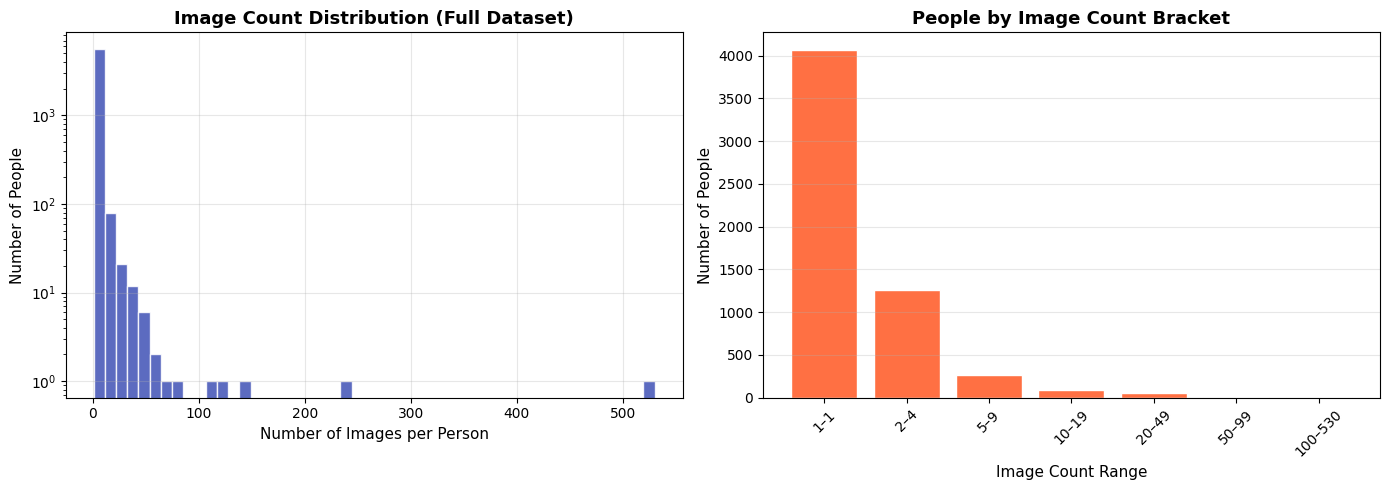

In [3]:
def parse_lfw_directory(lfw_dir):
    """
    Parse the LFW directory structure.

    Returns:
        dict: Mapping from person name → list of absolute image file paths.
    """
    person_to_images = {}

    for person_name in sorted(os.listdir(lfw_dir)):
        person_dir = os.path.join(lfw_dir, person_name)
        if not os.path.isdir(person_dir):
            continue

        images = []
        for img_file in sorted(os.listdir(person_dir)):
            if img_file.lower().endswith(('.jpg', '.jpeg', '.png')):
                images.append(os.path.join(person_dir, img_file))

        if images:
            person_to_images[person_name] = images

    return person_to_images
person_to_images = parse_lfw_directory(LFW_DIR)
total_people = len(person_to_images)
total_images = sum(len(imgs) for imgs in person_to_images.values())
counts = [len(imgs) for imgs in person_to_images.values()]

print(f" Full Dataset Statistics:")
print(f" Total individuals     : {total_people}")
print(f" Total images          : {total_images}")
print(f" Min images / person   : {min(counts)}")
print(f" Max images / person   : {max(counts)}")
print(f" Mean images / person  : {np.mean(counts):.2f}")
print(f" Median images / person: {np.median(counts):.0f}")
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.hist(counts, bins=50, color='#3F51B5', edgecolor='white', alpha=0.85)
plt.xlabel('Number of Images per Person', fontsize=11)
plt.ylabel('Number of People', fontsize=11)
plt.title('Image Count Distribution (Full Dataset)', fontsize=13, fontweight='bold')
plt.yscale('log')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
bins = [1, 2, 5, 10, 20, 50, 100, max(counts)+1]
hist_vals, bin_labels = [], []
for i in range(len(bins)-1):
    count = sum(1 for c in counts if bins[i] <= c < bins[i+1])
    hist_vals.append(count)
    bin_labels.append(f'{bins[i]}–{bins[i+1]-1}')
plt.bar(bin_labels, hist_vals, color='#FF7043', edgecolor='white')
plt.xlabel('Image Count Range', fontsize=11)
plt.ylabel('Number of People', fontsize=11)
plt.title('People by Image Count Bracket', fontsize=13, fontweight='bold')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

---
## 4.Data Filtering & Justification


Filtering Results (min 2 images/person):
People retained : 1,680 / 5,749
People removed  : 4,069
Images retained : 9,164 / 13,233
Images removed  : 4,069

👤 Top-10 Individuals by Image Count:
    1. George W Bush: 530 images
    2. Colin Powell: 236 images
    3. Tony Blair: 144 images
    4. Donald Rumsfeld: 121 images
    5. Gerhard Schroeder: 109 images
    6. Ariel Sharon: 77 images
    7. Hugo Chavez: 71 images
    8. Junichiro Koizumi: 60 images
    9. Jean Chretien: 55 images
   10. John Ashcroft: 53 images


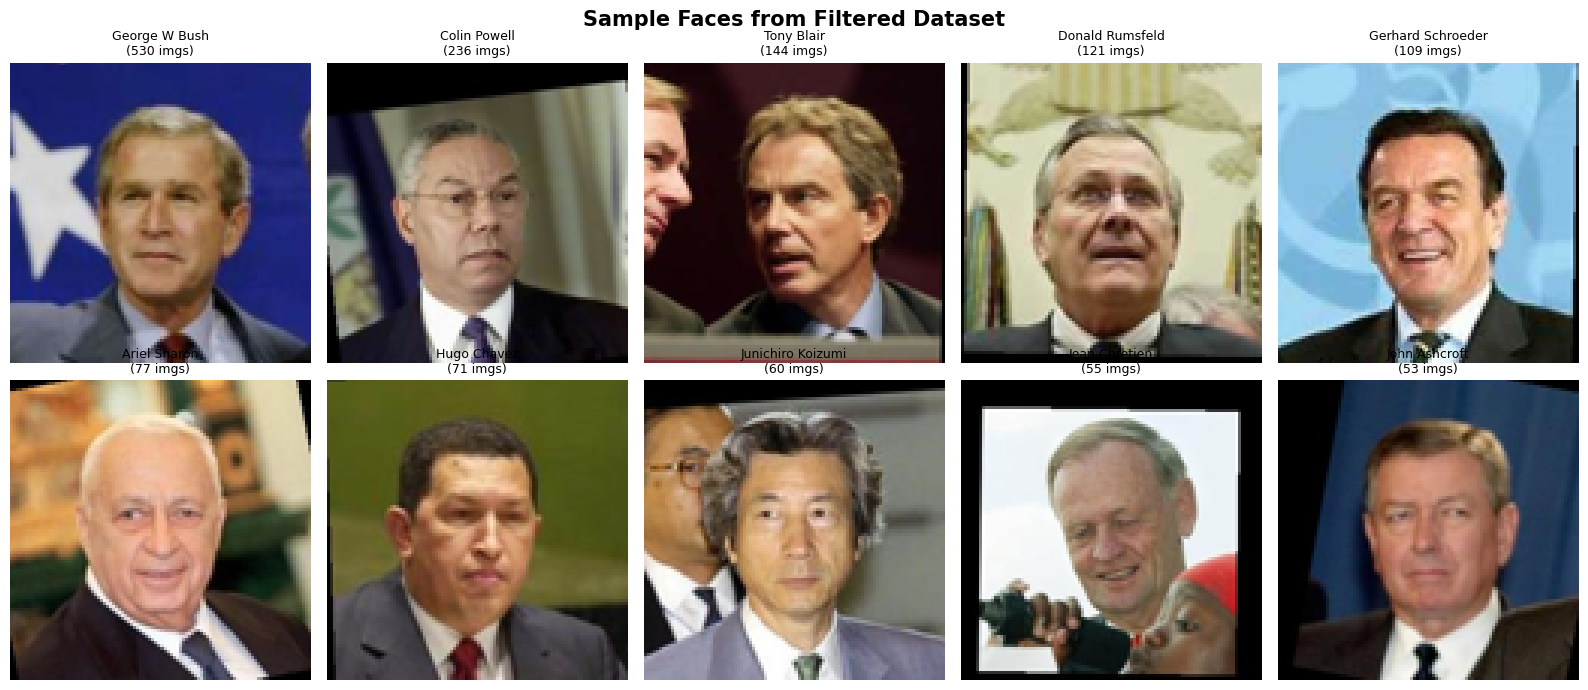

In [4]:
# Apply filter
filtered_people = {
    person: imgs
    for person, imgs in person_to_images.items()
    if len(imgs) >= MIN_IMAGES_PER_PERSON
}
filtered_images = sum(len(imgs) for imgs in filtered_people.values())
removed_people = total_people - len(filtered_people)
removed_images = total_images - filtered_images
print(f"Filtering Results (min {MIN_IMAGES_PER_PERSON} images/person):")
print(f"People retained : {len(filtered_people):,} / {total_people:,}")
print(f"People removed  : {removed_people:,}")
print(f"Images retained : {filtered_images:,} / {total_images:,}")
print(f"Images removed  : {removed_images:,}")
sorted_people = sorted(filtered_people.items(), key=lambda x: len(x[1]), reverse=True)
print(f"\n👤 Top-10 Individuals by Image Count:")
for rank, (name, imgs) in enumerate(sorted_people[:10], 1):
    print(f"   {rank:2d}. {name.replace('_', ' ')}: {len(imgs)} images")
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
fig.suptitle('Sample Faces from Filtered Dataset', fontsize=15, fontweight='bold')
for i, (name, imgs) in enumerate(sorted_people[:10]):
    row, col = i // 5, i % 5
    img = Image.open(imgs[0]).resize((IMG_SIZE, IMG_SIZE))
    axes[row, col].imshow(img)
    display_name = name.replace('_', ' ')
    if len(display_name) > 18:
        display_name = display_name[:16] + '…'
    axes[row, col].set_title(f'{display_name}\n({len(imgs)} imgs)', fontsize=9)
    axes[row, col].axis('off')
plt.tight_layout()
plt.show()

---
## 5.Pair Generation (for Contrastive Loss)


 Pair Generation Complete:
   Training   : 5,000 pairs (2500 pos / 2500 neg)
   Validation : 1,000 pairs (500 pos / 500 neg)


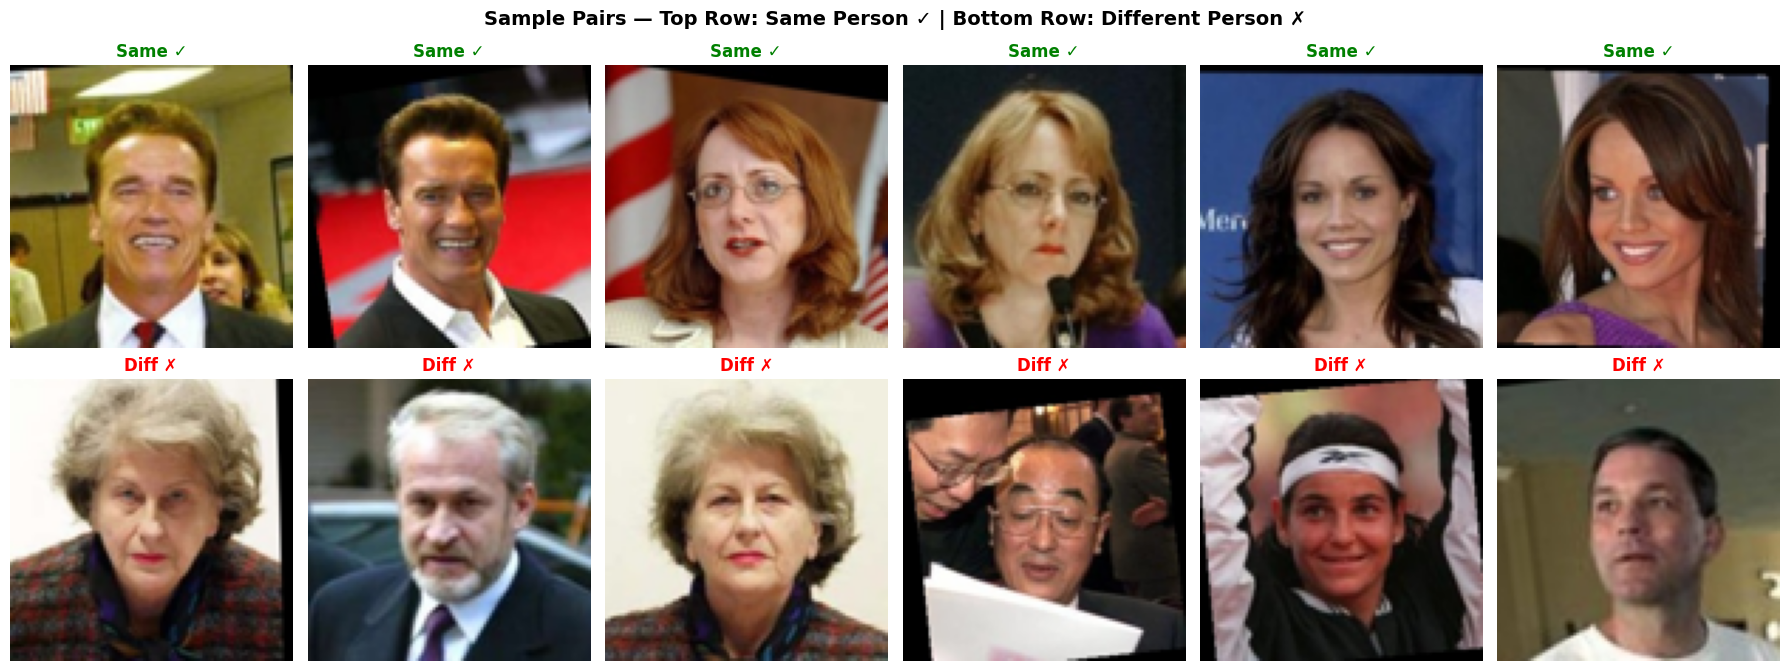

In [5]:
def generate_pairs(person_to_imgs, num_pairs, seed=42):
    """
    Generate balanced positive and negative pairs for contrastive learning.

    Args:
        person_to_imgs: Dict mapping person names to image paths.
        num_pairs: Total number of pairs to generate.
        seed: Random seed for reproducibility.

    Returns:
        List of (img_path_a, img_path_b, label) tuples.
        label = 1 for same person, 0 for different person.
    """
    rng = random.Random(seed)
    people_list = list(person_to_imgs.keys())
    num_positive = num_pairs // 2
    num_negative = num_pairs - num_positive
    pairs = []
    for _ in range(num_positive):
        person = rng.choice(people_list)
        imgs = person_to_imgs[person]
        img1, img2 = rng.sample(imgs, 2)
        pairs.append((img1, img2, 1))
    for _ in range(num_negative):
        p1, p2 = rng.sample(people_list, 2)
        img1 = rng.choice(person_to_imgs[p1])
        img2 = rng.choice(person_to_imgs[p2])
        pairs.append((img1, img2, 0))

    rng.shuffle(pairs)
    return pairs
train_pairs = generate_pairs(filtered_people, NUM_TRAIN_SAMPLES, seed=42)
val_pairs   = generate_pairs(filtered_people, NUM_VAL_SAMPLES,   seed=123)
train_pos = sum(1 for _, _, l in train_pairs if l == 1)
val_pos   = sum(1 for _, _, l in val_pairs   if l == 1)
print(f" Pair Generation Complete:")
print(f"   Training   : {len(train_pairs):,} pairs "
      f"({train_pos} pos / {len(train_pairs)-train_pos} neg)")
print(f"   Validation : {len(val_pairs):,} pairs "
      f"({val_pos} pos / {len(val_pairs)-val_pos} neg)")
fig, axes = plt.subplots(2, 6, figsize=(18, 7))
fig.suptitle('Sample Pairs — Top Row: Same Person ✓ | Bottom Row: Different Person ✗',
             fontsize=14, fontweight='bold')
pos_samples = [(a, b, l) for a, b, l in train_pairs if l == 1][:3]
neg_samples = [(a, b, l) for a, b, l in train_pairs if l == 0][:3]
for i, (a, b, _) in enumerate(pos_samples):
    axes[0, 2*i].imshow(Image.open(a).resize((IMG_SIZE, IMG_SIZE)))
    axes[0, 2*i].set_title('Same ✓', color='green', fontweight='bold')
    axes[0, 2*i].axis('off')
    axes[0, 2*i+1].imshow(Image.open(b).resize((IMG_SIZE, IMG_SIZE)))
    axes[0, 2*i+1].set_title('Same ✓', color='green', fontweight='bold')
    axes[0, 2*i+1].axis('off')
for i, (a, b, _) in enumerate(neg_samples):
    axes[1, 2*i].imshow(Image.open(a).resize((IMG_SIZE, IMG_SIZE)))
    axes[1, 2*i].set_title('Diff ✗', color='red', fontweight='bold')
    axes[1, 2*i].axis('off')
    axes[1, 2*i+1].imshow(Image.open(b).resize((IMG_SIZE, IMG_SIZE)))
    axes[1, 2*i+1].set_title('Diff ✗', color='red', fontweight='bold')
    axes[1, 2*i+1].axis('off')
plt.tight_layout()
plt.show()


## 6. Triplet Generation (for Triplet Loss)

 Triplet Generation Complete:
   Training triplets   : 5,000
   Validation triplets : 1,000


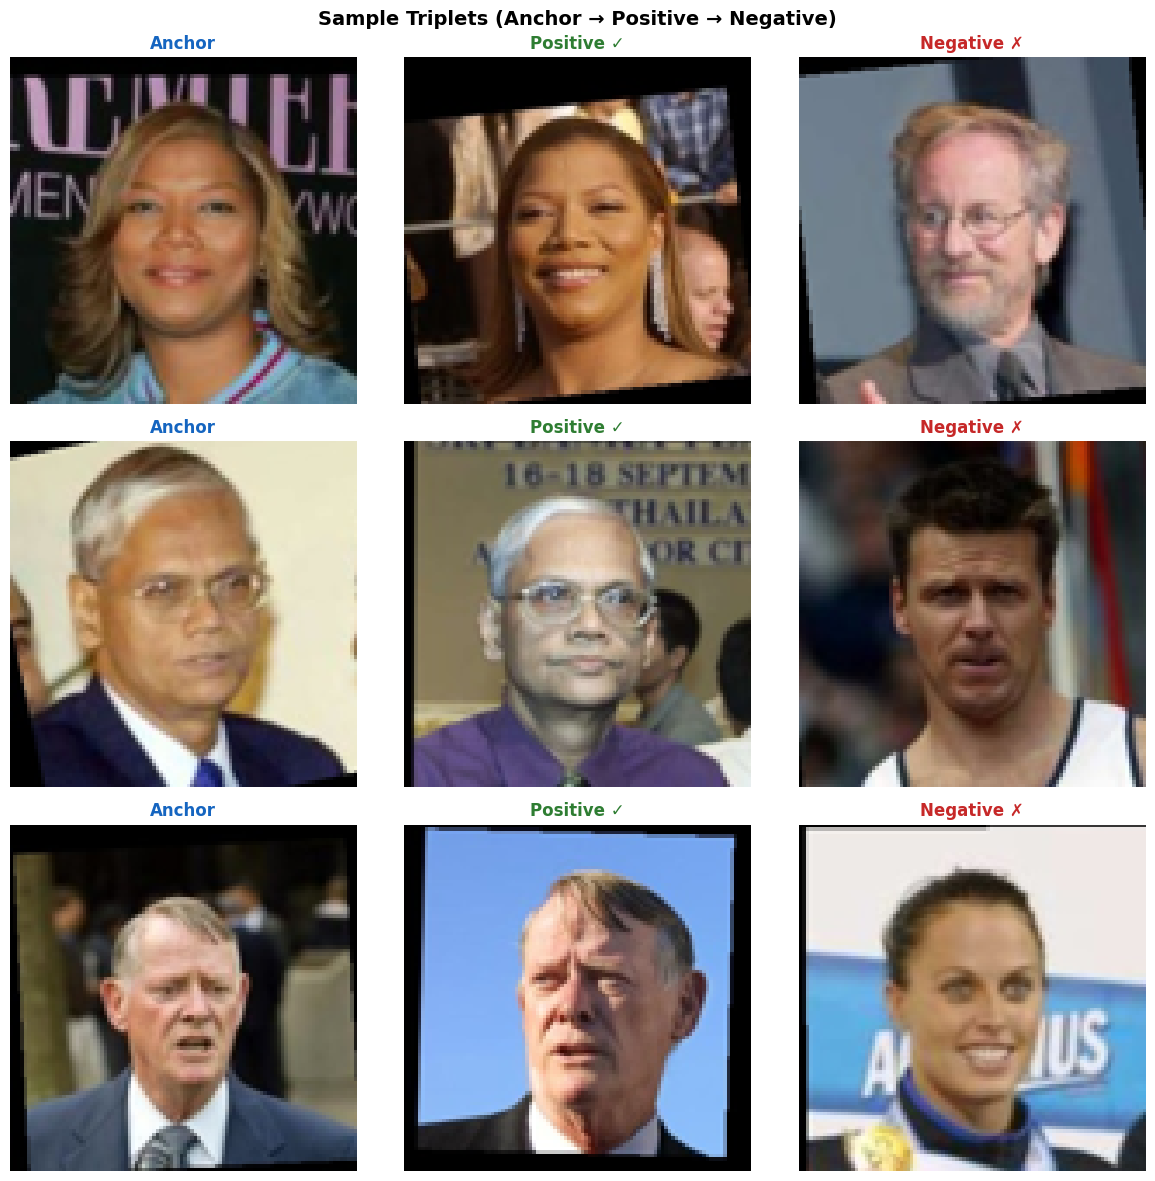

In [6]:
def generate_triplets(person_to_imgs, num_triplets, seed=42):
    """
    Generate (anchor, positive, negative) triplets for triplet learning.

    Args:
        person_to_imgs: Dict mapping person names to image paths.
        num_triplets: Number of triplets to generate.
        seed: Random seed for reproducibility.

    Returns:
        List of (anchor_path, positive_path, negative_path) tuples.
    """
    rng = random.Random(seed)
    people_list = list(person_to_imgs.keys())
    triplets = []
    for _ in range(num_triplets):
        anchor_person = rng.choice(people_list)
        anchor_imgs = person_to_imgs[anchor_person]
        anchor_img, positive_img = rng.sample(anchor_imgs, 2)
        negative_person = rng.choice([p for p in people_list if p != anchor_person])
        negative_img = rng.choice(person_to_imgs[negative_person])

        triplets.append((anchor_img, positive_img, negative_img))

    return triplets
train_triplets = generate_triplets(filtered_people, NUM_TRAIN_SAMPLES, seed=42)
val_triplets   = generate_triplets(filtered_people, NUM_VAL_SAMPLES,   seed=123)
print(f" Triplet Generation Complete:")
print(f"   Training triplets   : {len(train_triplets):,}")
print(f"   Validation triplets : {len(val_triplets):,}")
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
fig.suptitle('Sample Triplets (Anchor → Positive → Negative)', fontsize=14, fontweight='bold')
for i in range(3):
    anc, pos, neg = train_triplets[i]
    axes[i, 0].imshow(Image.open(anc).resize((IMG_SIZE, IMG_SIZE)))
    axes[i, 0].set_title('Anchor', color='#1565C0', fontweight='bold', fontsize=12)
    axes[i, 0].axis('off')
    axes[i, 1].imshow(Image.open(pos).resize((IMG_SIZE, IMG_SIZE)))
    axes[i, 1].set_title('Positive ✓', color='#2E7D32', fontweight='bold', fontsize=12)
    axes[i, 1].axis('off')
    axes[i, 2].imshow(Image.open(neg).resize((IMG_SIZE, IMG_SIZE)))
    axes[i, 2].set_title('Negative ✗', color='#C62828', fontweight='bold', fontsize=12)
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()

## 7. Image Loading Utilities

In [7]:
def load_image(path, img_size=IMG_SIZE):
    """Load a single image, resize, and normalize to [0, 1]."""
    img = Image.open(path).convert('RGB').resize((img_size, img_size))
    return np.array(img, dtype=np.float32) / 255.0


def prepare_pair_data(pairs, img_size=IMG_SIZE):
    """Load all pair images into numpy arrays for model.fit()."""
    print(f"   Loading {len(pairs)} pairs...")
    img_a  = np.array([load_image(p[0], img_size) for p in pairs])
    img_b  = np.array([load_image(p[1], img_size) for p in pairs])
    labels = np.array([p[2] for p in pairs], dtype=np.float32)
    print(f"    Shape: {img_a.shape} | dtype: {img_a.dtype}")
    return img_a, img_b, labels


def prepare_triplet_data(triplets, img_size=IMG_SIZE):
    """Load all triplet images into numpy arrays for model.fit()."""
    print(f"   Loading {len(triplets)} triplets...")
    anchors   = np.array([load_image(t[0], img_size) for t in triplets])
    positives = np.array([load_image(t[1], img_size) for t in triplets])
    negatives = np.array([load_image(t[2], img_size) for t in triplets])
    dummy_y   = np.zeros(len(triplets), dtype=np.float32)
    print(f"    Shape: {anchors.shape} | dtype: {anchors.dtype}")
    return anchors, positives, negatives, dummy_y


print(" Image loading utilities defined.")

 Image loading utilities defined.


## 8. Embedding Network Architectures

### 8.1 Custom CNN Embedding Network

In [8]:
def build_custom_cnn_embedding(input_shape=(IMG_SIZE, IMG_SIZE, 3),
                                embedding_dim=EMBEDDING_DIM):
    """
    Build a custom CNN embedding network from scratch.

    Architecture:
        Block 1: 32 filters (3×3) × 2 → MaxPool → Dropout(0.25)
        Block 2: 64 filters (3×3) × 2 → MaxPool → Dropout(0.25)
        Block 3: 128 filters (3×3) × 2 → MaxPool → Dropout(0.25)
        Block 4: 256 filters (3×3) × 1 → MaxPool → Dropout(0.25)
        Head:    Flatten → Dense(512) → BN → Dropout(0.5) → Dense(128) → L2 Norm

    Returns:
        Keras Model mapping input image → L2-normalized embedding vector.
    """
    inputs = Input(shape=input_shape)

    # Block 1: 32 filters
    x = layers.Conv2D(32, (3, 3), padding='same')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(32, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.25)(x)

    # Block 2: 64 filters
    x = layers.Conv2D(64, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(64, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.25)(x)

    #  Block 3: 128 filters
    x = layers.Conv2D(128, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(128, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.25)(x)

    # Block 4: 256 filters
    x = layers.Conv2D(256, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.25)(x)

    # Embedding Head
    x = layers.Flatten()(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(embedding_dim)(x)
    x = layers.Lambda(lambda t: tf.math.l2_normalize(t, axis=1),
                      name='l2_normalize')(x)

    return Model(inputs, x, name='custom_cnn_embedding')
test_model = build_custom_cnn_embedding()
test_model.summary()
del test_model

Model: "custom_cnn_embedding"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 100, 100, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 100, 100, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 100, 100, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 100, 100, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 100, 100, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 100, 100, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 50, 50, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 50, 50, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 50, 50, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 50, 50, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 25, 25, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 25, 25, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 25, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 25, 25, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 25, 25, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 5,371,808 (20.49 MB)

 Trainable params: 5,369,376 (20.48 MB)

 Non-trainable params: 2,432 (9.50 KB)

### 8.2 Transfer Learning Embedding Network (MobileNetV2)

In [9]:
def build_transfer_embedding(input_shape=(IMG_SIZE, IMG_SIZE, 3),
                              embedding_dim=EMBEDDING_DIM):
    """
    Build a transfer learning embedding network using MobileNetV2.

    Architecture:
        Rescale [0,1] → [-1,1]
        → MobileNetV2 (frozen, ImageNet weights)
        → GlobalAveragePooling2D
        → Dense(512) → BN → Dropout(0.5) → Dense(128) → L2 Norm

    Returns:
        Keras Model mapping input image → L2-normalized embedding vector.
    """
    inputs = Input(shape=input_shape)
 # Rescale from [0, 1] to [-1, 1] required by MobileNetV2
    x = layers.Lambda(lambda t: t * 2.0 - 1.0, name='rescale_to_neg1_1')(inputs)

    # Pre-trained MobileNetV2 backbone
    base_model = MobileNetV2(
        weights='imagenet',
        include_top=False,
        input_shape=input_shape
    )
    base_model.trainable = False

    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    #  Trainable Embedding Head
    x = layers.Dense(512, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(embedding_dim)(x)
    x = layers.Lambda(lambda t: tf.math.l2_normalize(t, axis=1),
                      name='l2_normalize')(x)

    return Model(inputs, x, name='transfer_embedding')
# Inspect architecture
test_model = build_transfer_embedding()
test_model.summary()
del test_model

/tmp/ipykernel_5160/2174503583.py:20: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "transfer_embedding"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale_to_neg1_1 (Lambda)      │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ l2_normalize (Lambda)           │ (None, 128)            │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,981,568 (11.37 MB)

 Trainable params: 722,560 (2.76 MB)

 Non-trainable params: 2,259,008 (8.62 MB)

## 9. Loss Functions (Manual Implementation)

### 9.1 Contrastive Loss

In [10]:
def create_contrastive_loss(margin=CONTRASTIVE_MARGIN):
    """
    Factory function that creates a contrastive loss with configurable margin.

    The inner function has the (y_true, y_pred) signature required by Keras.
    """
    def contrastive_loss(y_true, y_pred):
        """
        Manual implementation of Contrastive Loss.

        Args:
            y_true: Labels — 1.0 for same person, 0.0 for different.
            y_pred: Euclidean distance between embedding pairs.
        """
        y_true = tf.cast(y_true, tf.float32)
        # Same pair → minimize distance
        positive_loss = y_true * tf.square(y_pred)
        # Different pair → push apart beyond margin
        negative_loss = (1.0 - y_true) * tf.square(tf.maximum(margin - y_pred, 0.0))
        return tf.reduce_mean(positive_loss + negative_loss)
    return contrastive_loss
print(" Contrastive Loss defined (margin={})".format(CONTRASTIVE_MARGIN))

 Contrastive Loss defined (margin=1.0)


### 9.2 Triplet Loss

In [11]:
def create_triplet_loss(margin=TRIPLET_MARGIN, embedding_dim=EMBEDDING_DIM):
    """
    Factory function that creates a triplet loss with configurable margin.

    The model outputs concatenated embeddings [anchor | positive | negative],
    and this loss slices them apart to compute the triplet objective.
    """
    def triplet_loss(y_true, y_pred):
        """
        Manual implementation of Triplet Loss.

        Args:
            y_true: Dummy labels (not used — required by Keras API).
            y_pred: Concatenated embeddings [anchor | positive | negative]
                    with shape (batch_size, 3 × embedding_dim).
        """
        # Slice the concatenated embeddings
        anchor   = y_pred[:, :embedding_dim]
        positive = y_pred[:, embedding_dim : 2 * embedding_dim]
        negative = y_pred[:, 2 * embedding_dim:]
        # Squared Euclidean distances
        pos_dist = tf.reduce_sum(tf.square(anchor - positive), axis=1)
        neg_dist = tf.reduce_sum(tf.square(anchor - negative), axis=1)
        # Triplet loss with margin
        loss = tf.maximum(pos_dist - neg_dist + margin, 0.0)
        return tf.reduce_mean(loss)
    return triplet_loss


print(" Triplet Loss defined (margin={})".format(TRIPLET_MARGIN))

 Triplet Loss defined (margin=0.5)



## 10. Siamese Model Builders & Custom Metrics

In [12]:
def euclidean_distance(vectors):
    """Compute Euclidean distance between two embedding vectors."""
    v1, v2 = vectors
    return tf.sqrt(tf.reduce_sum(tf.square(v1 - v2), axis=1) + 1e-8)


def build_contrastive_siamese(embedding_network,
                               input_shape=(IMG_SIZE, IMG_SIZE, 3)):
    """
    Build a Siamese model for Contrastive Loss training.

    Input:  Two images  →  Shared embedding network  →  Euclidean distance
    Output: Scalar distance per pair.
    """
    input_a = Input(shape=input_shape, name='input_a')
    input_b = Input(shape=input_shape, name='input_b')

    # Shared weights — same embedding network processes both images
    emb_a = embedding_network(input_a)
    emb_b = embedding_network(input_b)
    # Euclidean distance between embeddings
    distance = layers.Lambda(euclidean_distance,
                             name='euclidean_distance')([emb_a, emb_b])

    model = Model(inputs=[input_a, input_b], outputs=distance,
                  name=f'siamese_contrastive_{embedding_network.name}')
    return model
def build_triplet_siamese(embedding_network,
                           input_shape=(IMG_SIZE, IMG_SIZE, 3)):
    """
    Build a Siamese model for Triplet Loss training.

    Input:  Three images (Anchor, Positive, Negative)
            → Shared embedding network
            → Concatenated embeddings
    Output: Concatenated embeddings [anchor | positive | negative].
    """
    input_anchor   = Input(shape=input_shape, name='anchor')
    input_positive = Input(shape=input_shape, name='positive')
    input_negative = Input(shape=input_shape, name='negative')
    # Shared weights — same embedding network processes all three
    emb_anchor   = embedding_network(input_anchor)
    emb_positive = embedding_network(input_positive)
    emb_negative = embedding_network(input_negative)
    # Concatenate for loss computation
    merged = layers.Concatenate(name='merged_embeddings')(
        [emb_anchor, emb_positive, emb_negative]
    )

    model = Model(inputs=[input_anchor, input_positive, input_negative],
                  outputs=merged,
                  name=f'siamese_triplet_{embedding_network.name}')
    return model
#Custom Accuracy Metrics

def create_contrastive_accuracy(threshold=0.5):
    """
    Accuracy for contrastive models.
    Correct if: same_pair → distance < threshold, diff_pair → distance ≥ threshold.
    """
    def contrastive_accuracy(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        predicted_same = tf.cast(y_pred < threshold, tf.float32)
        return tf.reduce_mean(tf.cast(tf.equal(predicted_same, y_true), tf.float32))
    return contrastive_accuracy
def create_triplet_accuracy(embedding_dim=EMBEDDING_DIM):
    """
    Accuracy for triplet models.
    Correct if d(anchor, positive) < d(anchor, negative).
    """
    def triplet_accuracy(y_true, y_pred):
        anchor   = y_pred[:, :embedding_dim]
        positive = y_pred[:, embedding_dim : 2 * embedding_dim]
        negative = y_pred[:, 2 * embedding_dim:]
        pos_dist = tf.reduce_sum(tf.square(anchor - positive), axis=1)
        neg_dist = tf.reduce_sum(tf.square(anchor - negative), axis=1)
        return tf.reduce_mean(tf.cast(pos_dist < neg_dist, tf.float32))
    return triplet_accuracy
print(" Siamese model builders and custom metrics defined.")

 Siamese model builders and custom metrics defined.


---
## 11. Training — All 4 Experiments

In [13]:
# Store results and inference models
all_histories = {}
inference_models = {}

Experiment 1: Custom CNN + Contrastive Loss

In [14]:
print("=" * 65)
print("   EXPERIMENT 1: Custom CNN + Contrastive Loss")
print("=" * 65)
# Prepare pair data
print("\n Preparing pair data...")
train_a, train_b, train_y = prepare_pair_data(train_pairs)
val_a, val_b, val_y = prepare_pair_data(val_pairs)
#  Build model
emb_net_1 = build_custom_cnn_embedding()
model_1 = build_contrastive_siamese(emb_net_1)
model_1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=create_contrastive_loss(margin=CONTRASTIVE_MARGIN),
    metrics=[create_contrastive_accuracy(threshold=0.5)]
)
model_1.summary()
#  Train
print(f"\n Training for {EPOCHS} epochs...")
history_1 = model_1.fit(
    [train_a, train_b], train_y,
    validation_data=([val_a, val_b], val_y),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    shuffle=True,
    verbose=1
)

all_histories['Custom CNN +\nContrastive'] = history_1.history
inference_models['Custom CNN +\nContrastive'] = model_1
#  Clean up
del train_a, train_b, train_y, val_a, val_b, val_y
gc.collect()
print("\n Experiment 1 Complete!")

   EXPERIMENT 1: Custom CNN + Contrastive Loss

 Preparing pair data...
   Loading 5000 pairs...
    Shape: (5000, 100, 100, 3) | dtype: float32
   Loading 1000 pairs...
    Shape: (1000, 100, 100, 3) | dtype: float32


Model: "siamese_contrastive_custom_cnn_embedding"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_a             │ (None, 100, 100,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_b             │ (None, 100, 100,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ custom_cnn_embeddi… │ (None, 128)       │  5,371,808 │ input_a[0][0],    │
│ (Functional)        │                   │            │ input_b[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ euclidean_distance  │ (None)            │          0 │ custom_cnn_embed… │
│ (Lambda)            │                   │            │ custom_cnn_embed… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,371,808 (20.49 MB)

 Trainable params: 5,369,376 (20.48 MB)

 Non-trainable params: 2,432 (9.50 KB)


 Training for 15 epochs...
Epoch 1/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 55s 190ms/step - contrastive_accuracy: 0.4994 - loss: 0.8907 - val_contrastive_accuracy: 0.5088 - val_loss: 0.4666
Epoch 2/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 12s 75ms/step - contrastive_accuracy: 0.5012 - loss: 0.7193 - val_contrastive_accuracy: 0.5420 - val_loss: 0.3409
Epoch 3/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 12s 77ms/step - contrastive_accuracy: 0.5255 - loss: 0.6281 - val_contrastive_accuracy: 0.5957 - val_loss: 0.4102
Epoch 4/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 12s 78ms/step - contrastive_accuracy: 0.5599 - loss: 0.5651 - val_contrastive_accuracy: 0.6035 - val_loss: 0.4647
Epoch 5/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 21s 80ms/step - contrastive_accuracy: 0.5866 - loss: 0.5219 - val_contrastive_accuracy: 0.6318 - val_loss: 0.4854
Epoch 6/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 13s 84ms/step - contrastive_accuracy: 0.6065 - loss: 0.4968 - val_contrastive_accuracy: 0.6533 - val_loss: 0.4849
Epoch 7/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 13s 86m

###  Experiment 2: Custom CNN + Triplet Loss

In [15]:
print("=" * 65)
print("   EXPERIMENT 2: Custom CNN + Triplet Loss")
print("=" * 65)
#  Prepare triplet data
print("\n Preparing triplet data...")
train_anc, train_pos, train_neg, train_dummy = prepare_triplet_data(train_triplets)
val_anc, val_pos, val_neg, val_dummy = prepare_triplet_data(val_triplets)
# Build model
emb_net_2 = build_custom_cnn_embedding()
model_2 = build_triplet_siamese(emb_net_2)
model_2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=create_triplet_loss(margin=TRIPLET_MARGIN),
    metrics=[create_triplet_accuracy()]
)

# Train
print(f"\n Training for {EPOCHS} epochs...")
history_2 = model_2.fit(
    [train_anc, train_pos, train_neg], train_dummy,
    validation_data=([val_anc, val_pos, val_neg], val_dummy),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    shuffle=True,
    verbose=1
)

all_histories['Custom CNN +\nTriplet'] = history_2.history

# Build inference model from trained embedding network
inf_a = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
inf_b = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
inf_dist = layers.Lambda(euclidean_distance)([emb_net_2(inf_a), emb_net_2(inf_b)])
inference_models['Custom CNN +\nTriplet'] = Model(inputs=[inf_a, inf_b], outputs=inf_dist)
del train_anc, train_pos, train_neg, train_dummy
del val_anc, val_pos, val_neg, val_dummy
gc.collect()
print("\n Experiment 2 Complete!")

   EXPERIMENT 2: Custom CNN + Triplet Loss

 Preparing triplet data...
   Loading 5000 triplets...
    Shape: (5000, 100, 100, 3) | dtype: float32
   Loading 1000 triplets...
    Shape: (1000, 100, 100, 3) | dtype: float32

 Training for 15 epochs...
Epoch 1/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 67s 265ms/step - loss: 0.4253 - triplet_accuracy: 0.6085 - val_loss: 0.4935 - val_triplet_accuracy: 0.6201
Epoch 2/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 20s 130ms/step - loss: 0.3544 - triplet_accuracy: 0.6931 - val_loss: 0.4154 - val_triplet_accuracy: 0.6797
Epoch 3/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 20s 126ms/step - loss: 0.3199 - triplet_accuracy: 0.7245 - val_loss: 0.3692 - val_triplet_accuracy: 0.7295
Epoch 4/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 18s 117ms/step - loss: 0.2987 - triplet_accuracy: 0.7365 - val_loss: 0.3234 - val_triplet_accuracy: 0.7656
Epoch 5/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 18s 116ms/step - loss: 0.2595 - triplet_accuracy: 0.7781 - val_loss: 0.3035 - val_triplet_accuracy: 0.7881
Epoch 6/15
157

### Experiment 3: MobileNetV2 (Transfer Learning) + Contrastive Loss

In [16]:
print("=" * 65)
print("   EXPERIMENT 3: MobileNetV2 + Contrastive Loss")
print("=" * 65)
#  Prepare pair data
print("\n Preparing pair data...")
train_a, train_b, train_y = prepare_pair_data(train_pairs)
val_a, val_b, val_y = prepare_pair_data(val_pairs)
# Build model
emb_net_3 = build_transfer_embedding()
model_3 = build_contrastive_siamese(emb_net_3)
model_3.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=create_contrastive_loss(margin=CONTRASTIVE_MARGIN),
    metrics=[create_contrastive_accuracy(threshold=0.5)]
)
model_3.summary()
#  Train
print(f"\n Training for {EPOCHS} epochs...")
history_3 = model_3.fit(
    [train_a, train_b], train_y,
    validation_data=([val_a, val_b], val_y),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    shuffle=True,
    verbose=1
)

all_histories['MobileNetV2 +\nContrastive'] = history_3.history
inference_models['MobileNetV2 +\nContrastive'] = model_3
del train_a, train_b, train_y, val_a, val_b, val_y
gc.collect()
print("\n Experiment 3 Complete!")

   EXPERIMENT 3: MobileNetV2 + Contrastive Loss

 Preparing pair data...
   Loading 5000 pairs...
    Shape: (5000, 100, 100, 3) | dtype: float32
   Loading 1000 pairs...
    Shape: (1000, 100, 100, 3) | dtype: float32


/tmp/ipykernel_5160/2174503583.py:20: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


Model: "siamese_contrastive_transfer_embedding"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_a             │ (None, 100, 100,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_b             │ (None, 100, 100,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transfer_embedding  │ (None, 128)       │  2,981,568 │ input_a[0][0],    │
│ (Functional)        │                   │            │ input_b[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ euclidean_distance  │ (None)            │          0 │ transfer_embeddi… │
│ (Lambda)            │                   │            │ transfer_embeddi… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,981,568 (11.37 MB)

 Trainable params: 722,560 (2.76 MB)

 Non-trainable params: 2,259,008 (8.62 MB)


 Training for 15 epochs...
Epoch 1/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 51s 180ms/step - contrastive_accuracy: 0.4994 - loss: 0.7843 - val_contrastive_accuracy: 0.5664 - val_loss: 0.5032
Epoch 2/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - contrastive_accuracy: 0.5104 - loss: 0.5636 - val_contrastive_accuracy: 0.6221 - val_loss: 0.4527
Epoch 3/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - contrastive_accuracy: 0.5615 - loss: 0.4806 - val_contrastive_accuracy: 0.6523 - val_loss: 0.4236
Epoch 4/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - contrastive_accuracy: 0.5997 - loss: 0.4333 - val_contrastive_accuracy: 0.6602 - val_loss: 0.3976
Epoch 5/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - contrastive_accuracy: 0.6192 - loss: 0.3924 - val_contrastive_accuracy: 0.6611 - val_loss: 0.3756
Epoch 6/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - contrastive_accuracy: 0.6336 - loss: 0.3631 - val_contrastive_accuracy: 0.6758 - val_loss: 0.3579
Epoch 7/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step

### Experiment 4: MobileNetV2 (Transfer Learning) + Triplet Loss

In [17]:
print("=" * 65)
print("   EXPERIMENT 4: MobileNetV2 + Triplet Loss")
print("=" * 65)

# Prepare triplet data
print("\n Preparing triplet data...")
train_anc, train_pos, train_neg, train_dummy = prepare_triplet_data(train_triplets)
val_anc, val_pos, val_neg, val_dummy = prepare_triplet_data(val_triplets)

#  Build model (fresh embedding network)
emb_net_4 = build_transfer_embedding()
model_4 = build_triplet_siamese(emb_net_4)
model_4.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=create_triplet_loss(margin=TRIPLET_MARGIN),
    metrics=[create_triplet_accuracy()]
)

# Train
print(f"\n Training for {EPOCHS} epochs...")
history_4 = model_4.fit(
    [train_anc, train_pos, train_neg], train_dummy,
    validation_data=([val_anc, val_pos, val_neg], val_dummy),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    shuffle=True,
    verbose=1
)

all_histories['MobileNetV2 +\nTriplet'] = history_4.history

# Build inference model from trained embedding network
inf_a2 = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
inf_b2 = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
inf_dist2 = layers.Lambda(euclidean_distance)([emb_net_4(inf_a2), emb_net_4(inf_b2)])
inference_models['MobileNetV2 +\nTriplet'] = Model(inputs=[inf_a2, inf_b2], outputs=inf_dist2)
del train_anc, train_pos, train_neg, train_dummy
del val_anc, val_pos, val_neg, val_dummy
gc.collect()
print("\n Experiment 4 Complete!")

   EXPERIMENT 4: MobileNetV2 + Triplet Loss

 Preparing triplet data...
   Loading 5000 triplets...
    Shape: (5000, 100, 100, 3) | dtype: float32
   Loading 1000 triplets...
    Shape: (1000, 100, 100, 3) | dtype: float32


/tmp/ipykernel_5160/2174503583.py:20: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(



 Training for 15 epochs...
Epoch 1/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 49s 181ms/step - loss: 0.3039 - triplet_accuracy: 0.7406 - val_loss: 0.2283 - val_triplet_accuracy: 0.8076
Epoch 2/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - loss: 0.2252 - triplet_accuracy: 0.8195 - val_loss: 0.2062 - val_triplet_accuracy: 0.8203
Epoch 3/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - loss: 0.1841 - triplet_accuracy: 0.8591 - val_loss: 0.1889 - val_triplet_accuracy: 0.8350
Epoch 4/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - loss: 0.1606 - triplet_accuracy: 0.8836 - val_loss: 0.1812 - val_triplet_accuracy: 0.8438
Epoch 5/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - loss: 0.1376 - triplet_accuracy: 0.9088 - val_loss: 0.1702 - val_triplet_accuracy: 0.8584
Epoch 6/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - loss: 0.1218 - triplet_accuracy: 0.9182 - val_loss: 0.1629 - val_triplet_accuracy: 0.8604
Epoch 7/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - loss: 0.1114 - triplet_accuracy: 0.9315 - val

---
## 12. Evaluation & Visualization

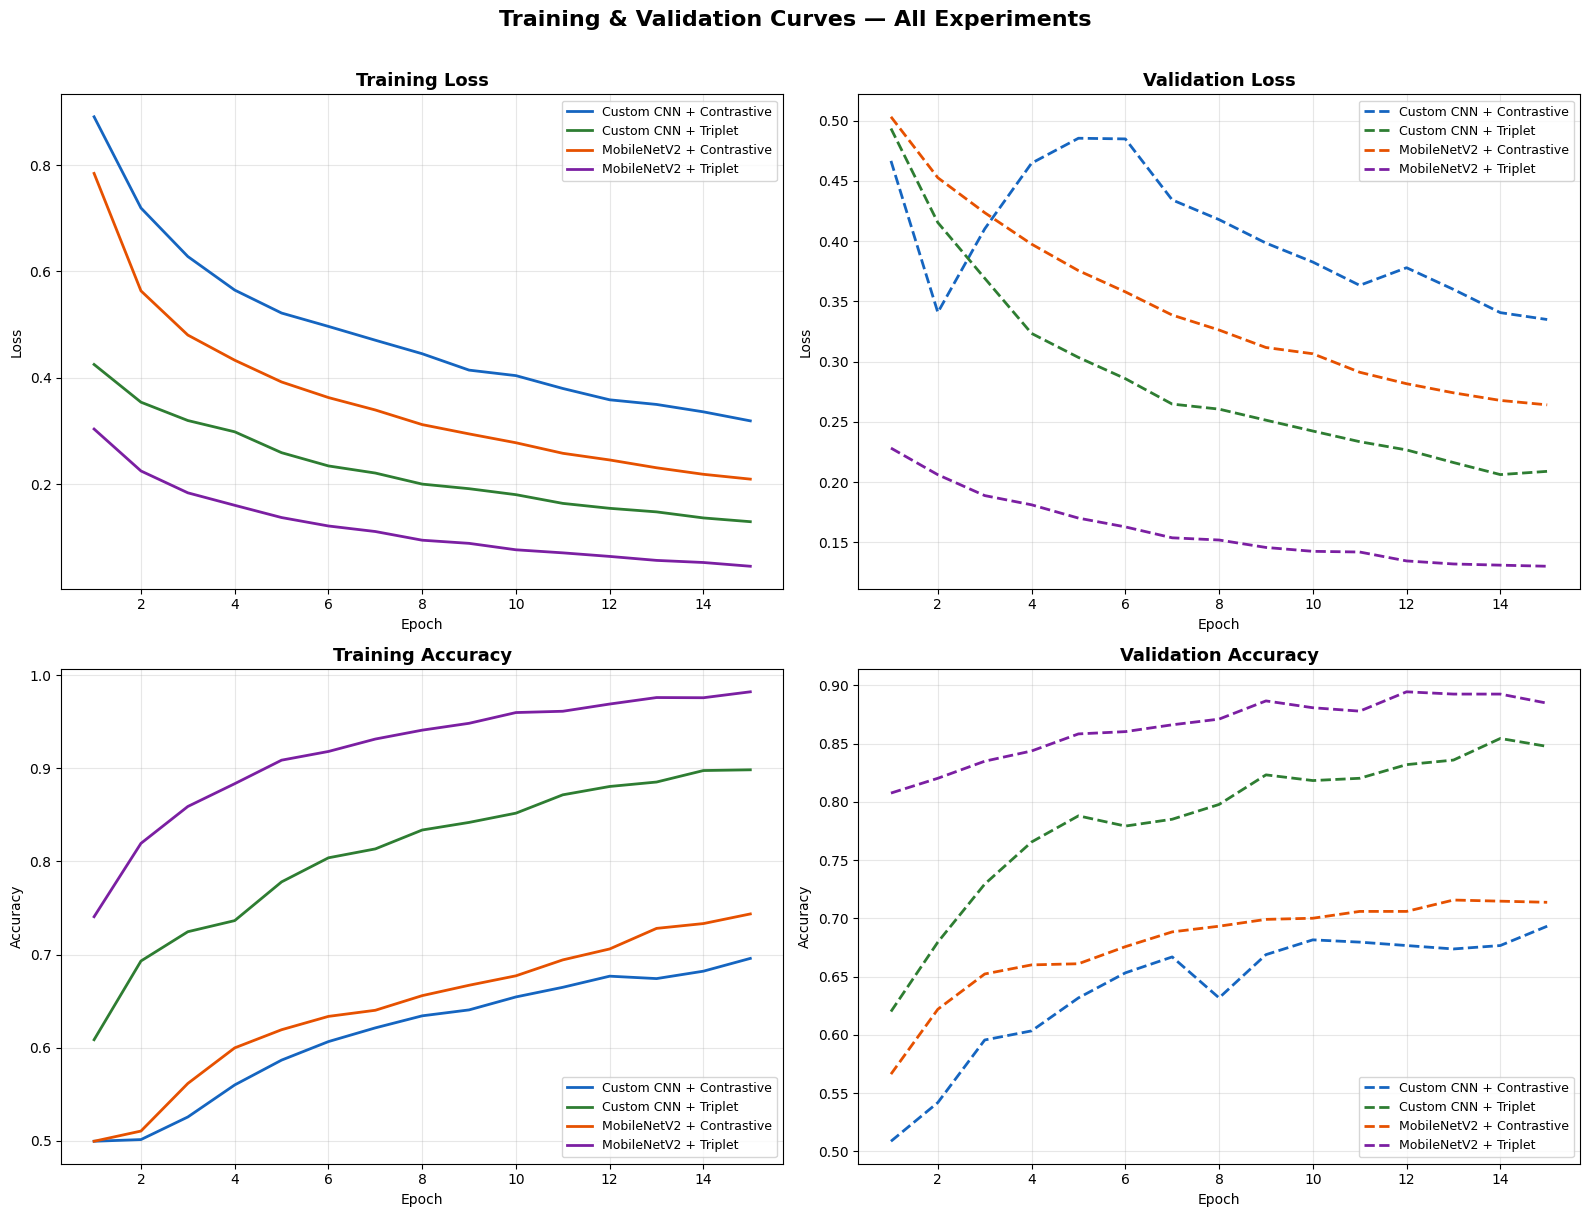


Experiment                            Train Loss     Val Loss    Train Acc      Val Acc
Custom CNN + Contrastive                  0.3193       0.3350       0.6959       0.6934
Custom CNN + Triplet                      0.1298       0.2090       0.8985       0.8477
MobileNetV2 + Contrastive                 0.2098       0.2642       0.7436       0.7139
MobileNetV2 + Triplet                     0.0461       0.1302       0.9823       0.8848


In [18]:
#  Color scheme for each experiment
exp_colors = {
    'Custom CNN +\nContrastive':   '#1565C0',
    'Custom CNN +\nTriplet':       '#2E7D32',
    'MobileNetV2 +\nContrastive':  '#E65100',
    'MobileNetV2 +\nTriplet':      '#7B1FA2',
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Training & Validation Curves — All Experiments',
             fontsize=16, fontweight='bold', y=1.01)

#  Plot 1: Training Loss
ax = axes[0, 0]
for name, hist in all_histories.items():
    ax.plot(range(1, len(hist['loss'])+1), hist['loss'],
            label=name.replace('\n', ' '), color=exp_colors[name], linewidth=2)
ax.set_title('Training Loss', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.legend(fontsize=9, loc='upper right')
ax.grid(True, alpha=0.3)

# Plot 2: Validation Loss
ax = axes[0, 1]
for name, hist in all_histories.items():
    ax.plot(range(1, len(hist['val_loss'])+1), hist['val_loss'],
            label=name.replace('\n', ' '), color=exp_colors[name],
            linewidth=2, linestyle='--')
ax.set_title('Validation Loss', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.legend(fontsize=9, loc='upper right')
ax.grid(True, alpha=0.3)

#  Plot 3: Training Accuracy
ax = axes[1, 0]
for name, hist in all_histories.items():
    acc_key = [k for k in hist.keys() if 'accuracy' in k and 'val' not in k][0]
    ax.plot(range(1, len(hist[acc_key])+1), hist[acc_key],
            label=name.replace('\n', ' '), color=exp_colors[name], linewidth=2)
ax.set_title('Training Accuracy', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy')
ax.legend(fontsize=9, loc='lower right')
ax.grid(True, alpha=0.3)

#  Plot 4: Validation Accuracy
ax = axes[1, 1]
for name, hist in all_histories.items():
    val_acc_key = [k for k in hist.keys() if 'accuracy' in k and 'val' in k][0]
    ax.plot(range(1, len(hist[val_acc_key])+1), hist[val_acc_key],
            label=name.replace('\n', ' '), color=exp_colors[name],
            linewidth=2, linestyle='--')
ax.set_title('Validation Accuracy', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy')
ax.legend(fontsize=9, loc='lower right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#  Print final metrics summary
print("\n" + "=" * 90)
print(f"{'Experiment':<35} {'Train Loss':>12} {'Val Loss':>12} {'Train Acc':>12} {'Val Acc':>12}")
print("=" * 90)
for name, hist in all_histories.items():
    acc_key     = [k for k in hist.keys() if 'accuracy' in k and 'val' not in k][0]
    val_acc_key = [k for k in hist.keys() if 'accuracy' in k and 'val' in k][0]
    display_name = name.replace('\n', ' ')
    print(f"{display_name:<35} {hist['loss'][-1]:>12.4f} {hist['val_loss'][-1]:>12.4f} "
          f"{hist[acc_key][-1]:>12.4f} {hist[val_acc_key][-1]:>12.4f}")
print("=" * 90)

### 12.2 Distance Distribution Plots

 Computing distances for: Custom CNN + Contrastive...
 Computing distances for: Custom CNN + Triplet...
 Computing distances for: MobileNetV2 + Contrastive...
 Computing distances for: MobileNetV2 + Triplet...


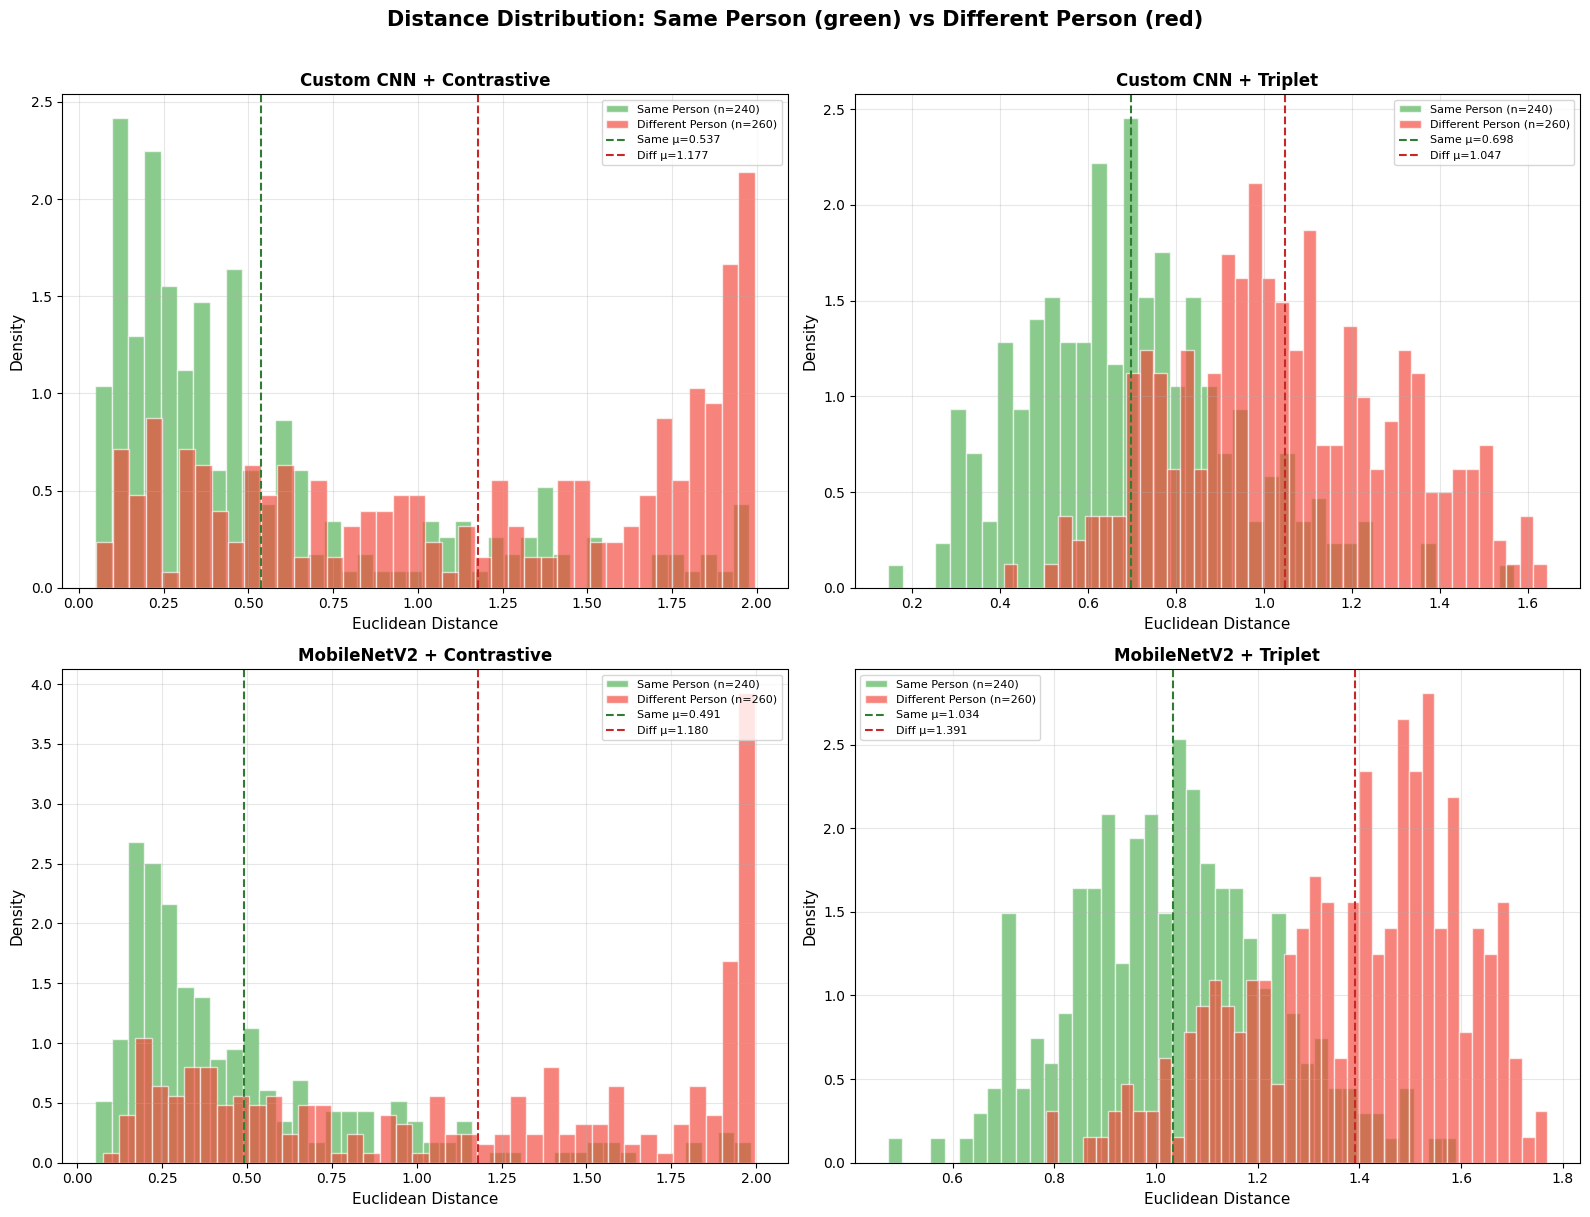

In [19]:
def compute_pairwise_distances(model, pairs, img_size=IMG_SIZE, max_samples=500):
    """
    Compute distances for a set of pairs using the given inference model.

    Returns:
        same_distances: List of distances for positive pairs (same person).
        diff_distances: List of distances for negative pairs (different person).
    """
    same_distances = []
    diff_distances = []

    sample_pairs = pairs[:max_samples]

    for img_path_a, img_path_b, label in sample_pairs:
        img_a = np.expand_dims(load_image(img_path_a, img_size), axis=0)
        img_b = np.expand_dims(load_image(img_path_b, img_size), axis=0)

        pred = model.predict([img_a, img_b], verbose=0)
        distance = float(np.squeeze(pred))

        if label == 1:
            same_distances.append(distance)
        else:
            diff_distances.append(distance)

    return same_distances, diff_distances


# Compute and plot
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Distance Distribution: Same Person (green) vs Different Person (red)',
             fontsize=15, fontweight='bold', y=1.01)

for idx, (name, model) in enumerate(inference_models.items()):
    row, col = idx // 2, idx % 2
    ax = axes[row, col]

    print(f" Computing distances for: {name.replace(chr(10), ' ')}...")
    same_dist, diff_dist = compute_pairwise_distances(model, val_pairs)

    ax.hist(same_dist, bins=40, alpha=0.65, color='#4CAF50',
            label=f'Same Person (n={len(same_dist)})', density=True, edgecolor='white')
    ax.hist(diff_dist, bins=40, alpha=0.65, color='#F44336',
            label=f'Different Person (n={len(diff_dist)})', density=True, edgecolor='white')
    ax.axvline(x=np.mean(same_dist), color='#2E7D32', linestyle='--',
               linewidth=1.5, label=f'Same μ={np.mean(same_dist):.3f}')
    ax.axvline(x=np.mean(diff_dist), color='#C62828', linestyle='--',
               linewidth=1.5, label=f'Diff μ={np.mean(diff_dist):.3f}')
    ax.set_xlabel('Euclidean Distance', fontsize=11)
    ax.set_ylabel('Density', fontsize=11)
    ax.set_title(name.replace('\n', ' '), fontweight='bold', fontsize=12)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 12.3 Optimal Threshold Analysis


In [20]:
def find_optimal_threshold(same_distances, diff_distances, num_thresholds=100):
    """
    Find the optimal distance threshold by maximizing accuracy.

    Returns:
        best_threshold, best_accuracy
    """
    all_distances = same_distances + diff_distances
    min_d, max_d = min(all_distances), max(all_distances)
    thresholds = np.linspace(min_d, max_d, num_thresholds)
    best_acc = 0
    best_thresh = 0
    for thresh in thresholds:
        # Same pairs: correct if distance < threshold
        tp = sum(1 for d in same_distances if d < thresh)
        # Different pairs: correct if distance >= threshold
        tn = sum(1 for d in diff_distances if d >= thresh)

        acc = (tp + tn) / (len(same_distances) + len(diff_distances))
        if acc > best_acc:
            best_acc = acc
            best_thresh = thresh

    return best_thresh, best_acc
print(" Optimal Thresholds per Model:")
print(f"{'Model':<40} {'Threshold':>12} {'Accuracy':>12}")
print("-" * 66)

optimal_thresholds = {}
for name, model in inference_models.items():
    same_d, diff_d = compute_pairwise_distances(model, val_pairs)
    thresh, acc = find_optimal_threshold(same_d, diff_d)
    optimal_thresholds[name] = thresh
    display_name = name.replace('\n', ' ')
    print(f"{display_name:<40} {thresh:>12.4f} {acc:>11.2%}")

 Optimal Thresholds per Model:
Model                                       Threshold     Accuracy
------------------------------------------------------------------
Custom CNN + Contrastive                       0.6772      73.20%
Custom CNN + Triplet                           0.8864      77.40%
MobileNetV2 + Contrastive                      1.0145      73.40%
MobileNetV2 + Triplet                          1.1929      80.40%


---
## 13. Inference Pipeline

In [21]:
def verify_faces(img_path_1, img_path_2, model, threshold=0.5,
                 model_name="Model"):
    """
    Face Verification Inference Pipeline.

    Args:
        img_path_1: Path to the first face image.
        img_path_2: Path to the second face image.
        model: Trained Siamese model (outputs Euclidean distance).
        threshold: Decision threshold — distance < threshold → same person.
        model_name: Display name of the model.

    Returns:
        distance (float): Euclidean distance between face embeddings.
        is_same (bool): True if the model predicts same person.
    """
    # Load and preprocess
    img1 = load_image(img_path_1)
    img2 = load_image(img_path_2)

    # Predict distance
    pred = model.predict(
        [np.expand_dims(img1, 0), np.expand_dims(img2, 0)], verbose=0
    )
    distance = float(np.squeeze(pred))
    is_same = distance < threshold

    # Visualization
    fig, axes = plt.subplots(1, 3, figsize=(14, 5),
                              gridspec_kw={'width_ratios': [1, 0.6, 1]})

    # Image 1
    axes[0].imshow(img1)
    axes[0].set_title('Image 1', fontsize=13, fontweight='bold')
    axes[0].axis('off')

    # Image 2
    axes[2].imshow(img2)
    axes[2].set_title('Image 2', fontsize=13, fontweight='bold')
    axes[2].axis('off')

    # Decision panel
    axes[1].axis('off')
    result_text = "SAME\nPERSON" if is_same else "DIFFERENT\nPERSON"
    result_color = '#4CAF50' if is_same else '#F44336'
    symbol = '✓' if is_same else '✗'

    axes[1].text(0.5, 0.65, symbol, fontsize=48, ha='center', va='center',
                 color=result_color, fontweight='bold',
                 transform=axes[1].transAxes)
    axes[1].text(0.5, 0.40, result_text, fontsize=15, ha='center', va='center',
                 color=result_color, fontweight='bold',
                 transform=axes[1].transAxes)
    axes[1].text(0.5, 0.18, f'Distance: {distance:.4f}', fontsize=12,
                 ha='center', va='center', color='#333333',
                 transform=axes[1].transAxes)
    axes[1].text(0.5, 0.08, f'Threshold: {threshold:.4f}', fontsize=10,
                 ha='center', va='center', color='#888888',
                 transform=axes[1].transAxes)

    fig.suptitle(f'Face Verification — {model_name}',
                 fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.show()

    return distance, is_same

####  Demo: Inference on Validation Set Pairs

╔═══════════════════════════════════════════════════════════════╗
║       INFERENCE DEMO — POSITIVE PAIR (Same Person)           ║
╚═══════════════════════════════════════════════════════════════╝



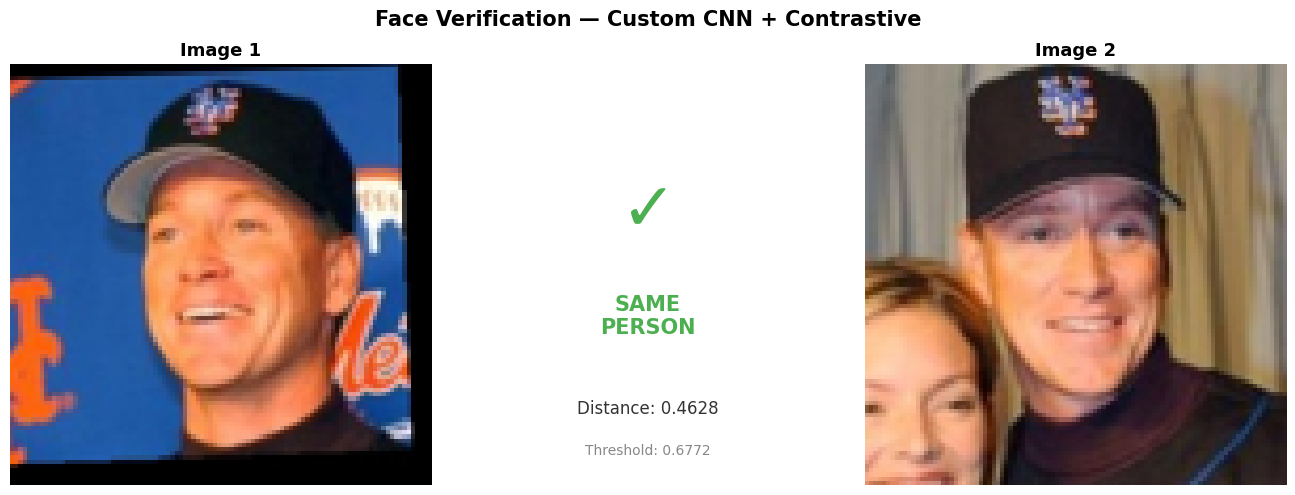

  Custom CNN + Contrastive: dist=0.4628, threshold=0.6772 →  CORRECT



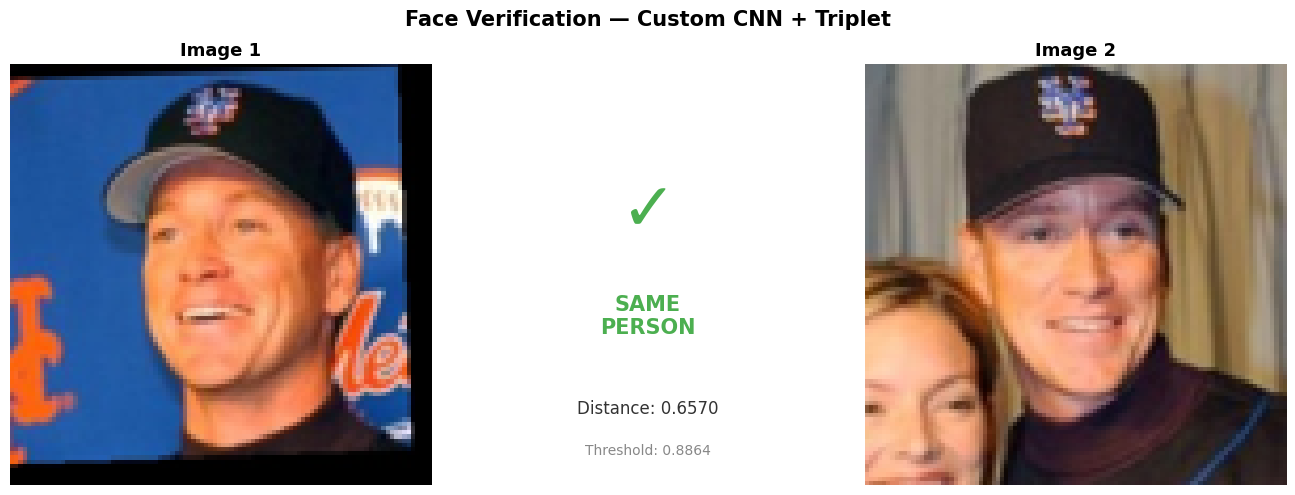

  Custom CNN + Triplet: dist=0.6570, threshold=0.8864 →  CORRECT



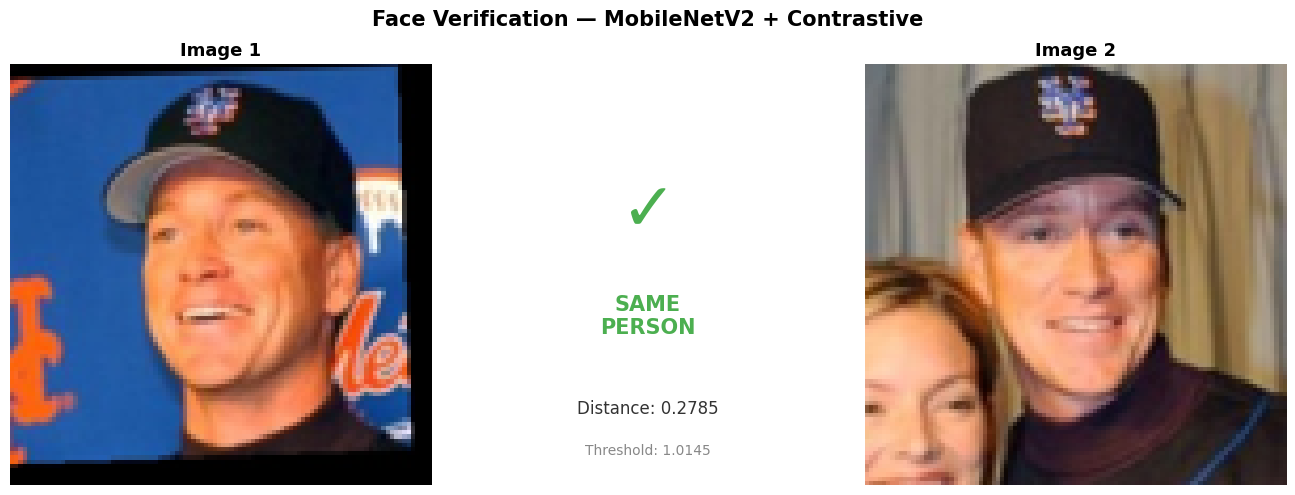

  MobileNetV2 + Contrastive: dist=0.2785, threshold=1.0145 →  CORRECT



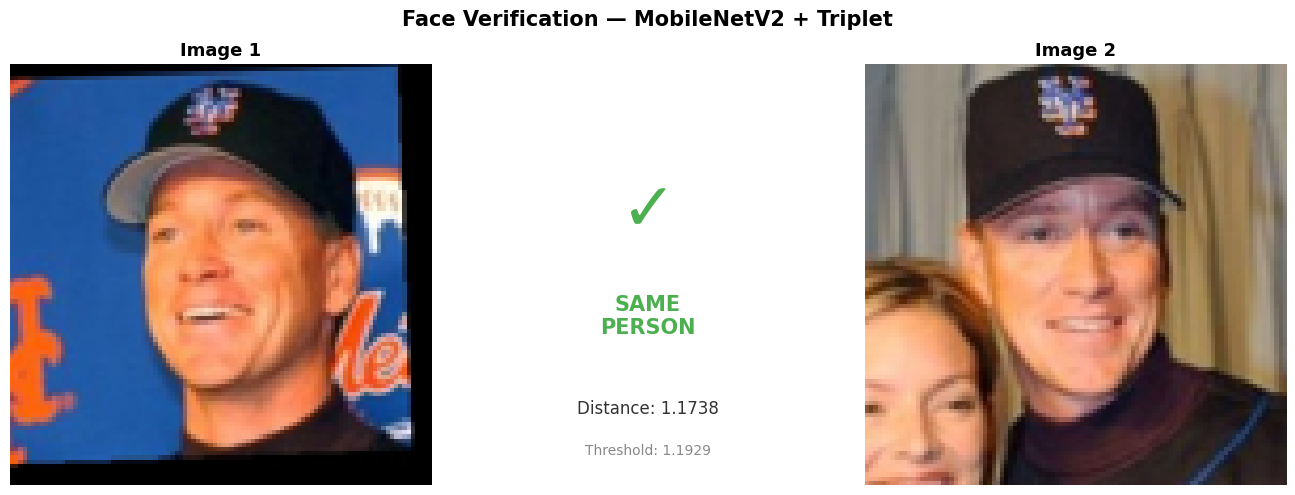

  MobileNetV2 + Triplet: dist=1.1738, threshold=1.1929 →  CORRECT


╔═══════════════════════════════════════════════════════════════╗
║       INFERENCE DEMO — NEGATIVE PAIR (Different Person)      ║
╚═══════════════════════════════════════════════════════════════╝



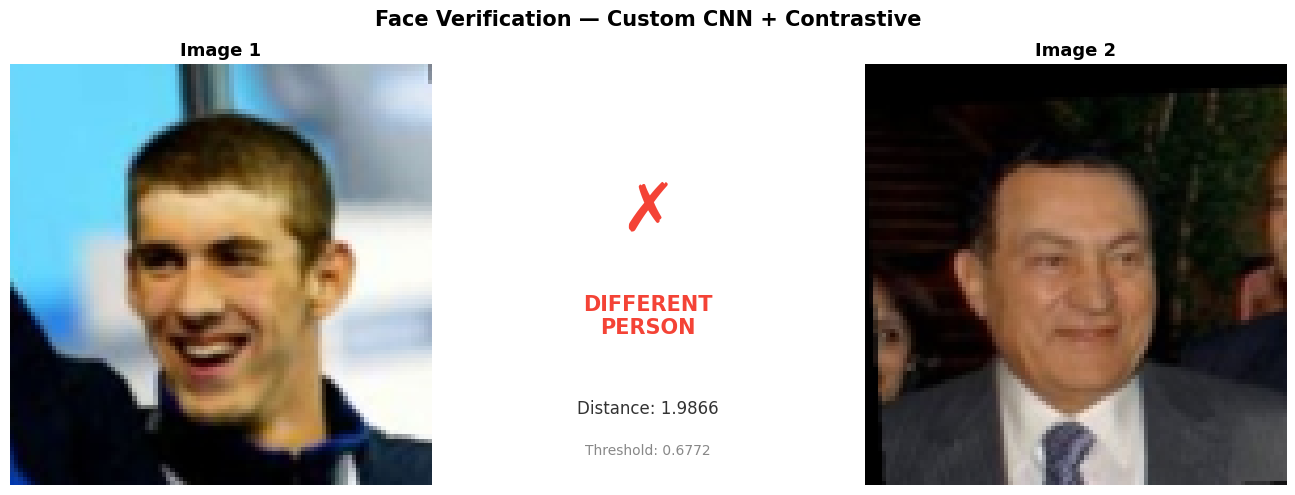

  Custom CNN + Contrastive: dist=1.9866, threshold=0.6772 →  CORRECT



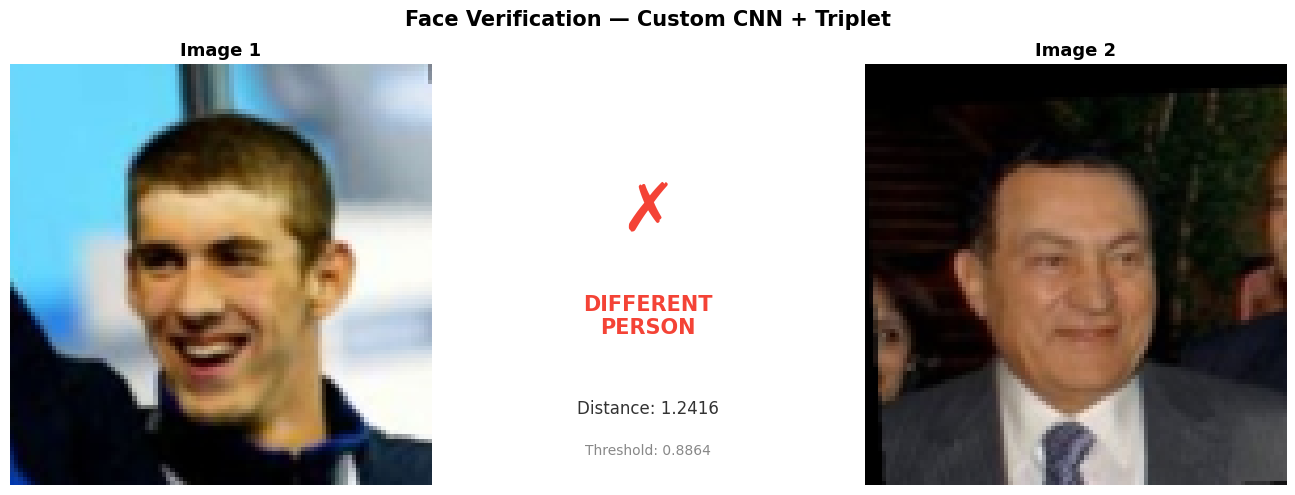

  Custom CNN + Triplet: dist=1.2416, threshold=0.8864 →  CORRECT



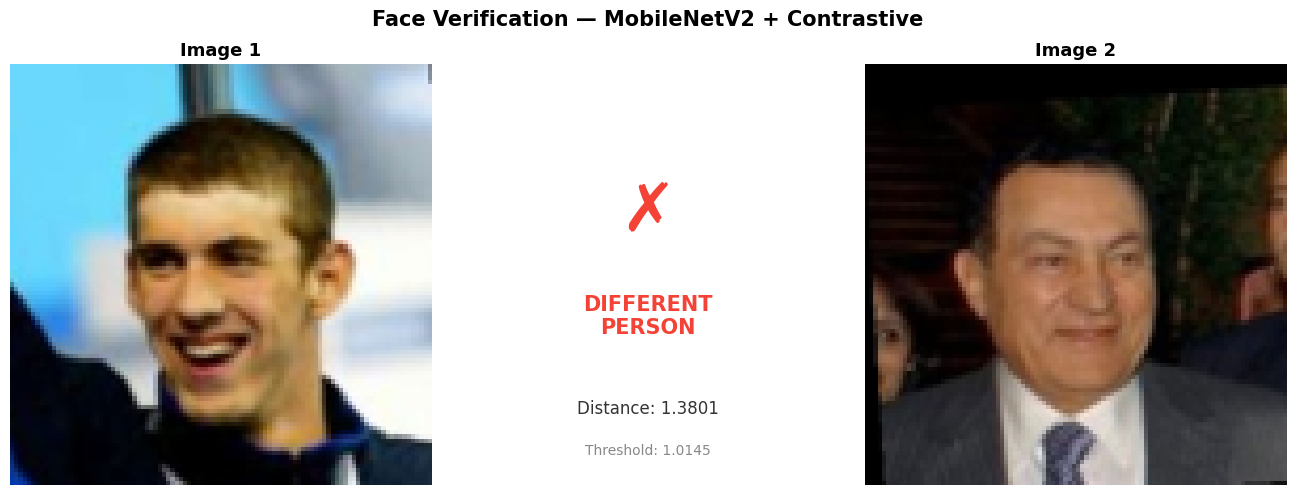

  MobileNetV2 + Contrastive: dist=1.3801, threshold=1.0145 →  CORRECT



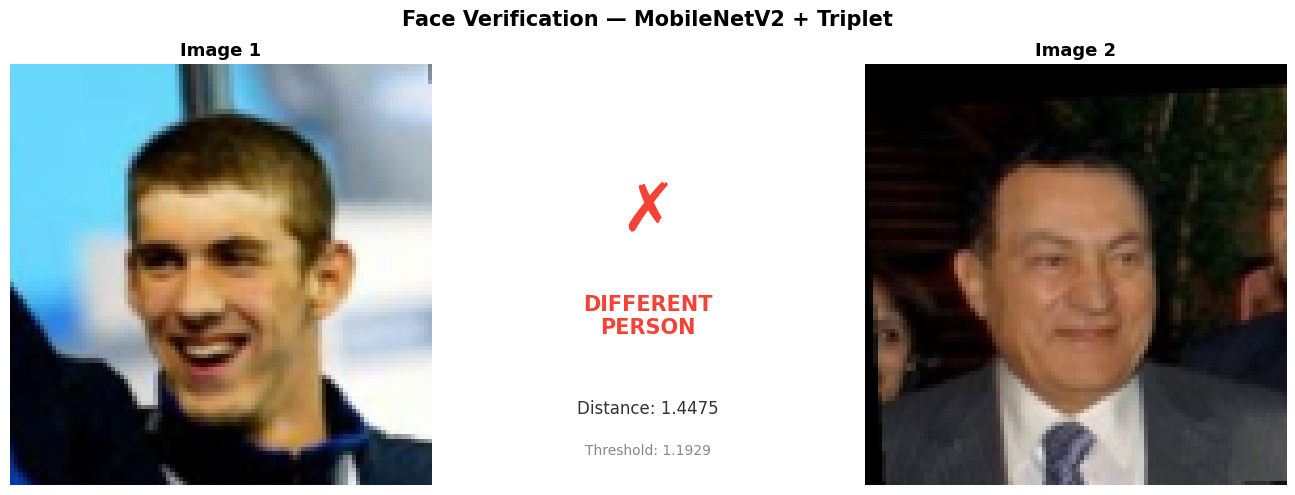

  MobileNetV2 + Triplet: dist=1.4475, threshold=1.1929 →  CORRECT



In [22]:
# Select one positive and one negative pair from validation set
demo_pos = next((a, b, l) for a, b, l in val_pairs if l == 1)
demo_neg = next((a, b, l) for a, b, l in val_pairs if l == 0)
# Use the best performing inference model for demonstration
print("╔" + "═" * 63 + "╗")
print("║       INFERENCE DEMO — POSITIVE PAIR (Same Person)           ║")
print("╚" + "═" * 63 + "╝\n")

for name, model in inference_models.items():
    display_name = name.replace('\n', ' ')
    thresh = optimal_thresholds.get(name, 0.5)
    dist, same = verify_faces(demo_pos[0], demo_pos[1], model,
                              threshold=thresh, model_name=display_name)
    status = " CORRECT" if same else " INCORRECT"
    print(f"  {display_name}: dist={dist:.4f}, threshold={thresh:.4f} → {status}\n")

print("\n" + "╔" + "═" * 63 + "╗")
print("║       INFERENCE DEMO — NEGATIVE PAIR (Different Person)      ║")
print("╚" + "═" * 63 + "╝\n")

for name, model in inference_models.items():
    display_name = name.replace('\n', ' ')
    thresh = optimal_thresholds.get(name, 0.5)
    dist, same = verify_faces(demo_neg[0], demo_neg[1], model,
                              threshold=thresh, model_name=display_name)
    status = " CORRECT" if not same else " INCORRECT"
    print(f"  {display_name}: dist={dist:.4f}, threshold={thresh:.4f} → {status}\n")

####  Additional Inference: Multiple Unseen Pairs

  Extended Inference Testing (10 random validation pairs)


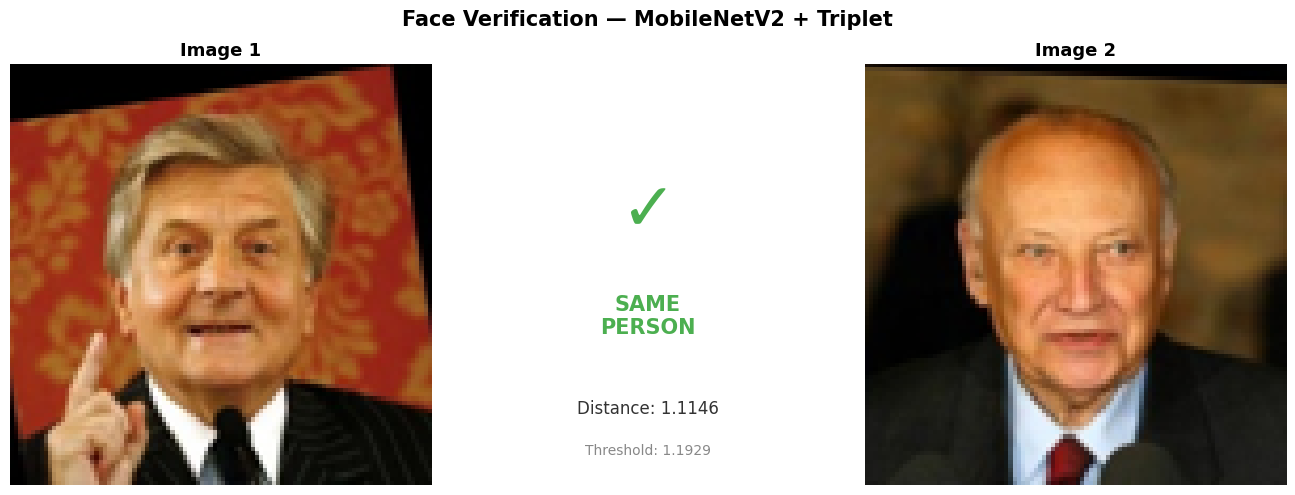

  Pair 1: True=Different | Dist=1.1146 | ❌


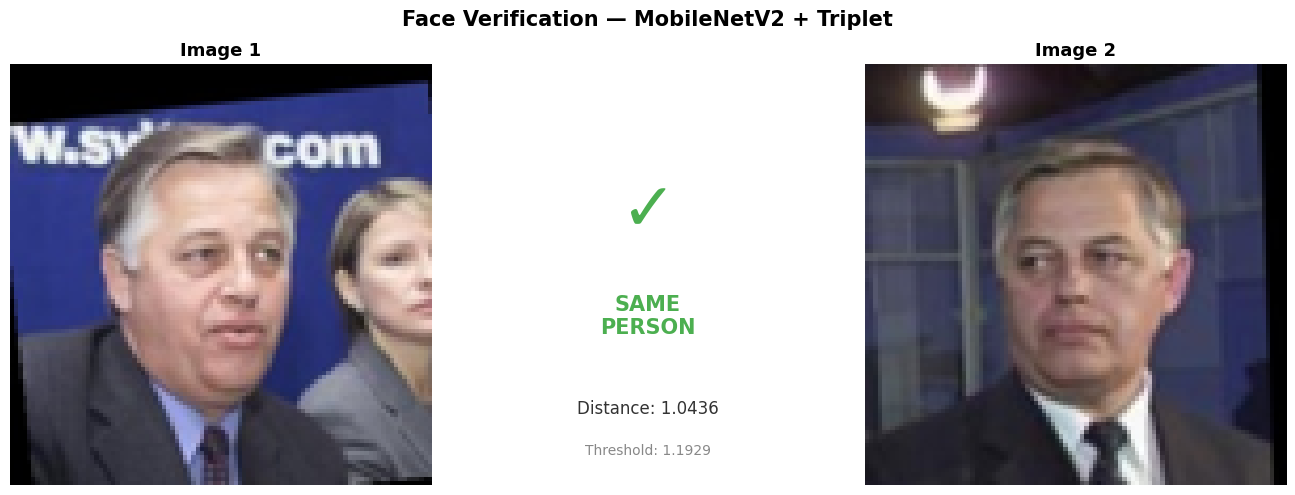

  Pair 2: True=Same      | Dist=1.0436 | ✅


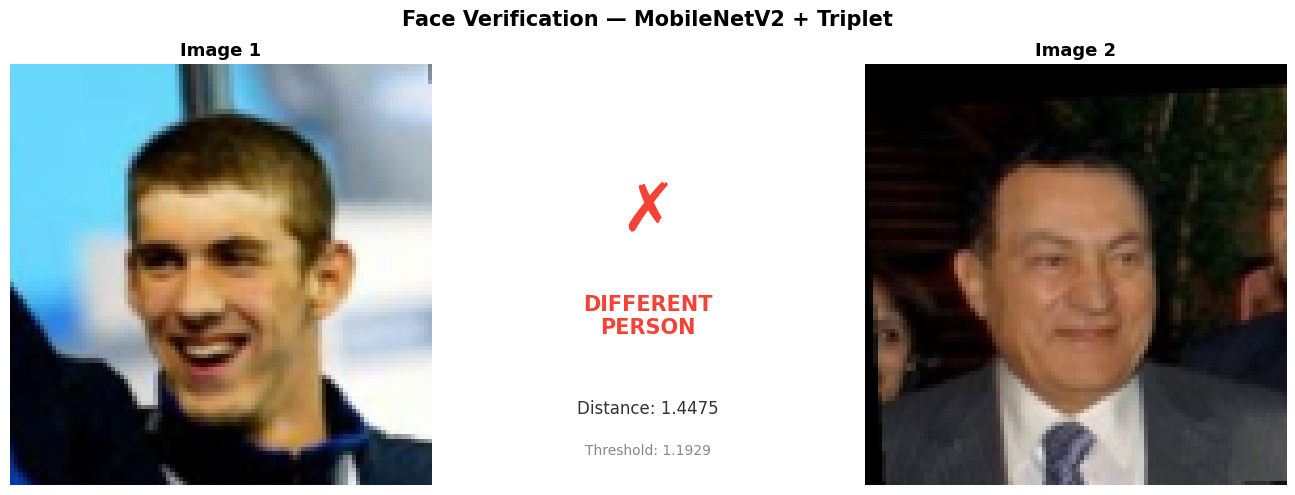

  Pair 3: True=Different | Dist=1.4475 | ✅


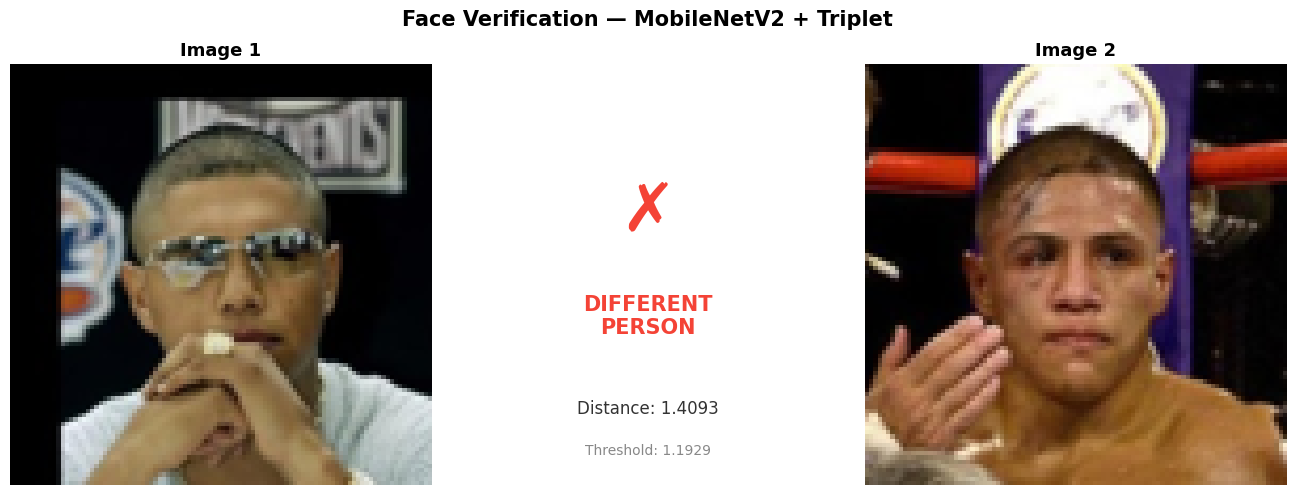

  Pair 4: True=Same      | Dist=1.4093 | ❌


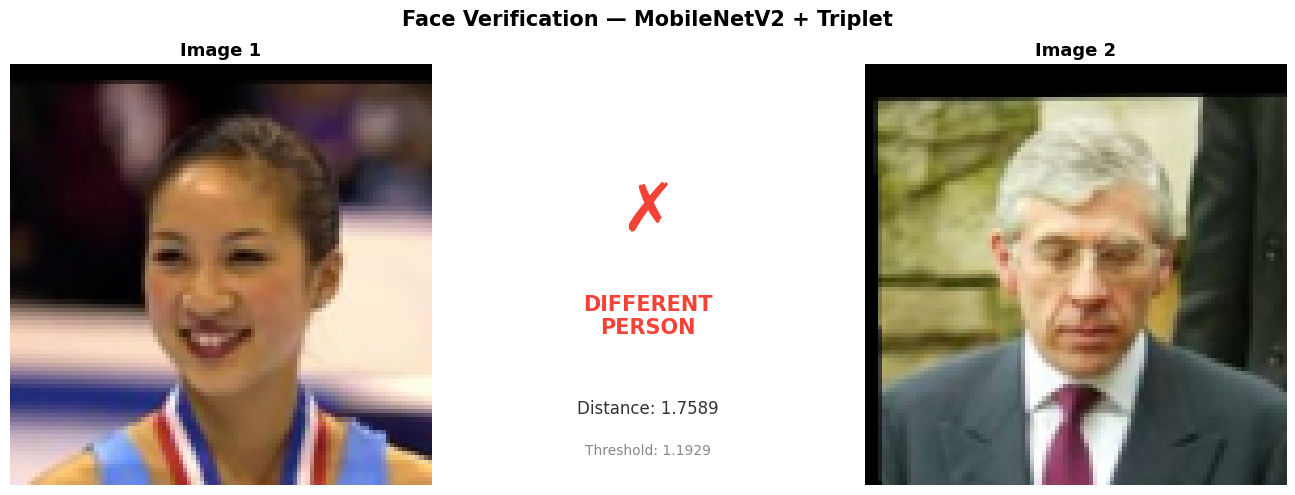

  Pair 5: True=Different | Dist=1.7589 | ✅


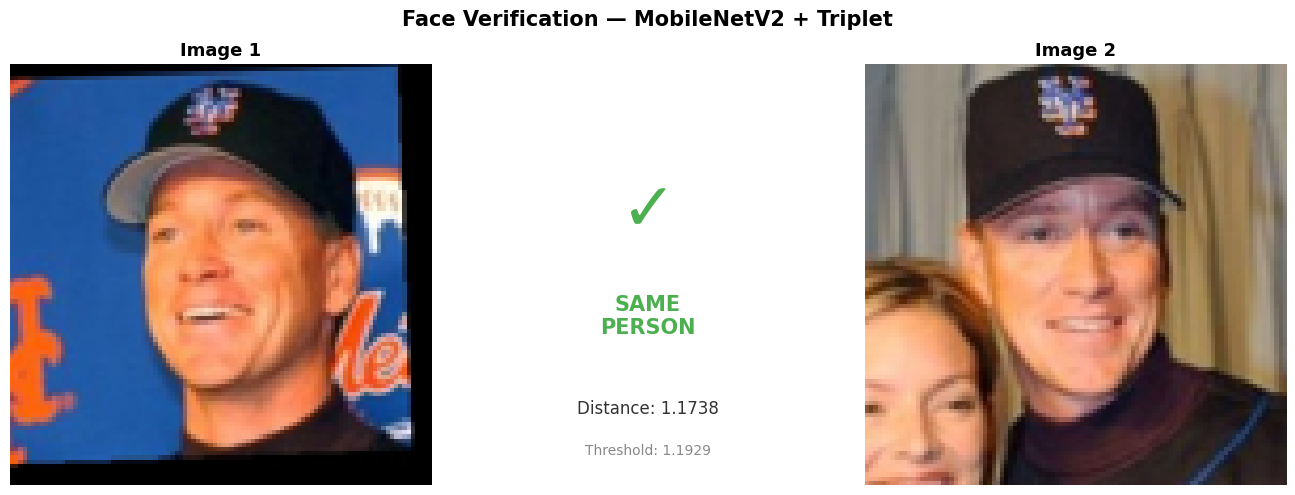

  Pair 6: True=Same      | Dist=1.1738 | ✅


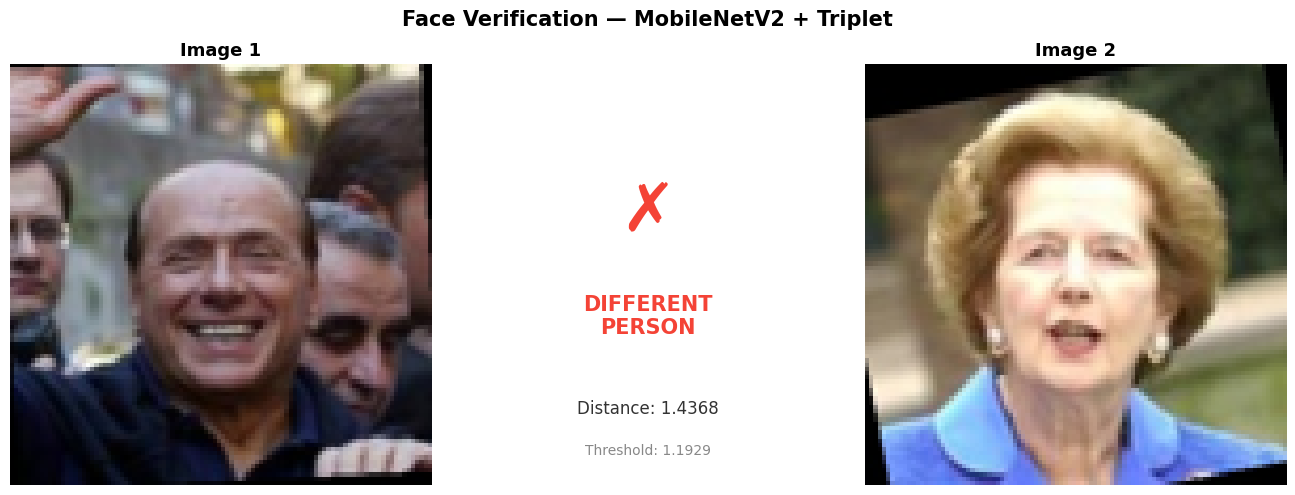

  Pair 7: True=Different | Dist=1.4368 | ✅


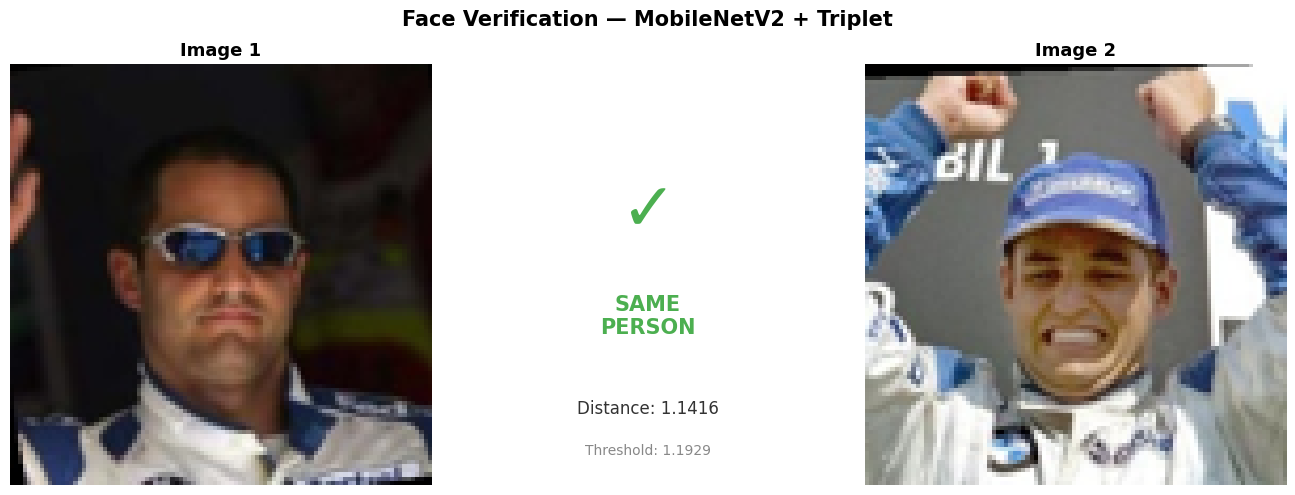

  Pair 8: True=Same      | Dist=1.1416 | ✅


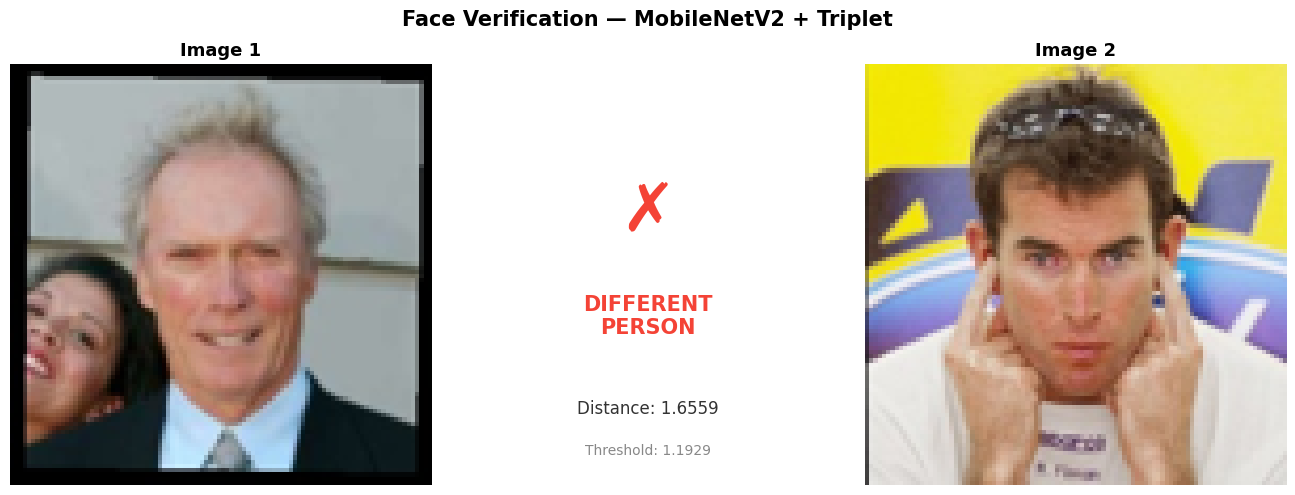

  Pair 9: True=Different | Dist=1.6559 | ✅


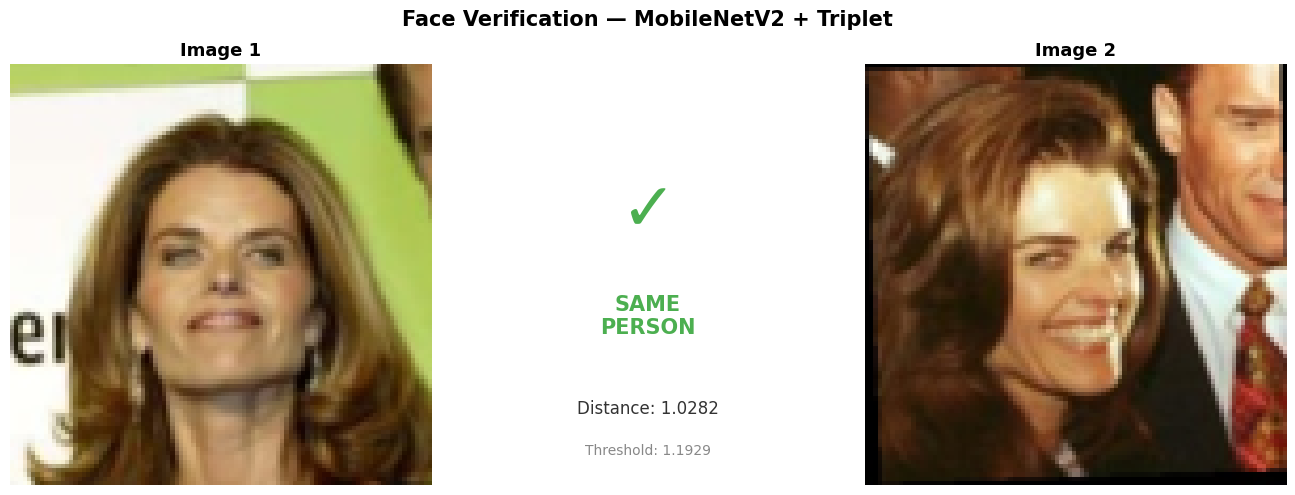

  Pair 10: True=Same      | Dist=1.0282 | ✅

 Inference Accuracy: 8/10 = 80.0%


In [23]:
# Test on several more validation pairs
print("=" * 70)
print("  Extended Inference Testing (10 random validation pairs)")
print("=" * 70)

# Pick the best model based on optimal threshold accuracy
best_model_name = max(optimal_thresholds, key=lambda k: optimal_thresholds[k])
best_model = inference_models[best_model_name]
best_thresh = optimal_thresholds[best_model_name]
display_best = best_model_name.replace('\n', ' ')

# Use a mix of positive and negative pairs
test_pairs = (
    [(a, b, l) for a, b, l in val_pairs if l == 1][:5] +
    [(a, b, l) for a, b, l in val_pairs if l == 0][:5]
)
random.shuffle(test_pairs)

correct = 0
for i, (a, b, true_label) in enumerate(test_pairs):
    dist, pred_same = verify_faces(a, b, best_model,
                                    threshold=best_thresh,
                                    model_name=display_best)
    is_correct = (pred_same == bool(true_label))
    correct += int(is_correct)
    label_str = "Same" if true_label == 1 else "Different"
    status = "✅" if is_correct else "❌"
    print(f"  Pair {i+1}: True={label_str:9s} | Dist={dist:.4f} | {status}")

print(f"\n Inference Accuracy: {correct}/{len(test_pairs)} = {correct/len(test_pairs):.1%}")